In [ ]:
!pip install nibabel

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

DATASET_PATH = "/content/drive/MyDrive/Master_SIIA/BraTS-Africa"

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Contents:")

for item in os.listdir(DATASET_PATH):
    print("-", item)

Dataset exists: True
Contents:
- 95_Glioma
- 51_OtherNeoplasms


In [ ]:
import os

glioma_path = os.path.join(DATASET_PATH, "95_Glioma")
other_path = os.path.join(DATASET_PATH, "51_OtherNeoplasms")

glioma_patients = [
    f for f in os.listdir(glioma_path)
    if os.path.isdir(os.path.join(glioma_path, f))
]

other_patients = [
    f for f in os.listdir(other_path)
    if os.path.isdir(os.path.join(other_path, f))
]

print("Number of Glioma patients:", len(glioma_patients))
print("Number of Other Neoplasms patients:", len(other_patients))
print("Total patients:", len(glioma_patients) + len(other_patients))

Number of Glioma patients: 95
Number of Other Neoplasms patients: 51
Total patients: 146


In [ ]:
# Check the files of all Glioma patients

required_suffixes = ["t1n.nii.gz", "t1c.nii.gz", "t2f.nii.gz", "t2w.nii.gz", "seg.nii.gz"]

missing_patients = []

for patient in glioma_patients:
    patient_path = os.path.join(glioma_path, patient)
    files = os.listdir(patient_path)

    missing = []

    for suffix in required_suffixes:
        if not any(f.endswith(suffix) for f in files):
            missing.append(suffix)

    if missing:
        missing_patients.append((patient, missing))

print("Glioma patients checked:", len(glioma_patients))
print("Patients with missing files:", len(missing_patients))

if len(missing_patients) == 0:
    print("✅ All Glioma patients have the 5 required files.")
else:
    print("⚠️ Missing files found:")
    for patient, missing in missing_patients:
        print(patient, "->", missing)

Glioma patients checked: 95
Patients with missing files: 0
✅ All Glioma patients have the 5 required files.


In [ ]:
import nibabel as nib
import os

patient = "BraTS-SSA-00002-000"
patient_path = os.path.join(glioma_path, patient)

t1n_file = [f for f in os.listdir(patient_path) if f.endswith("t1n.nii.gz")][0]
seg_file = [f for f in os.listdir(patient_path) if f.endswith("seg.nii.gz")][0]

t1n_path = os.path.join(patient_path, t1n_file)
seg_path = os.path.join(patient_path, seg_file)

t1n_img = nib.load(t1n_path)
seg_img = nib.load(seg_path)

print("T1n shape:", t1n_img.shape)
print("T1n voxel spacing:", t1n_img.header.get_zooms())

print("Segmentation shape:", seg_img.shape)
print("Segmentation voxel spacing:", seg_img.header.get_zooms())

T1n shape: (240, 240, 155)
T1n voxel spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Segmentation shape: (240, 240, 155)
Segmentation voxel spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))


In [ ]:
import nibabel as nib
import numpy as np
import os

patient = "BraTS-SSA-00002-000"

patient_path = os.path.join(glioma_path, patient)

seg_file = [
    f for f in os.listdir(patient_path)
    if f.endswith("seg.nii.gz")
][0]

seg_path = os.path.join(patient_path, seg_file)

seg_img = nib.load(seg_path)
seg = seg_img.get_fdata()

print("Segmentation shape:", seg.shape)
print("Unique labels:", np.unique(seg))

Segmentation shape: (240, 240, 155)
Unique labels: [0. 1. 2. 3.]


In [ ]:
# Count the number of voxels for each segmentation label

unique_labels, counts = np.unique(seg, return_counts=True)

for label, count in zip(unique_labels, counts):
    percentage = (count / seg.size) * 100

    print(
        f"Label {int(label)}: "
        f"{count:,} voxels "
        f"({percentage:.2f}%)"
    )

Label 0: 8,709,539 voxels (97.55%)
Label 1: 6,603 voxels (0.07%)
Label 2: 190,334 voxels (2.13%)
Label 3: 21,524 voxels (0.24%)


Selected slice: 78


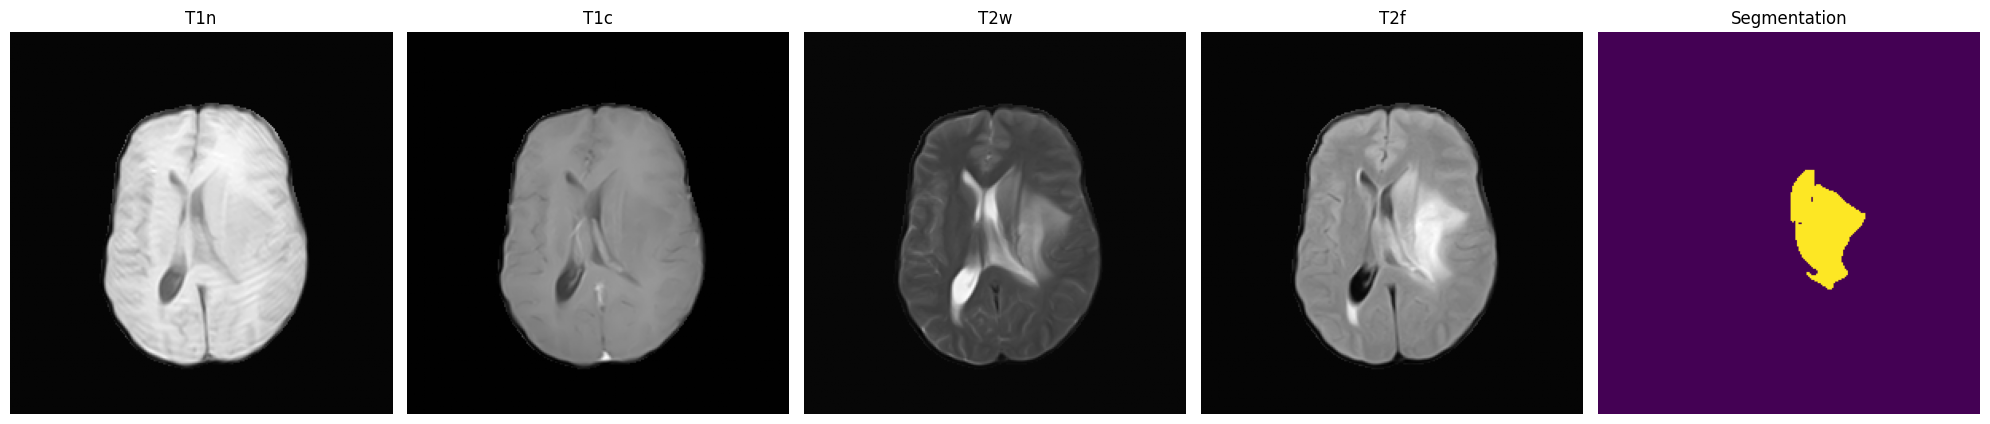

In [ ]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import os

# Patient
patient = "BraTS-SSA-00002-000"
patient_path = os.path.join(glioma_path, patient)

# Load MRI modalities
t1n = nib.load(
    os.path.join(patient_path,
                 [f for f in os.listdir(patient_path) if f.endswith("t1n.nii.gz")][0])
).get_fdata()

t1c = nib.load(
    os.path.join(patient_path,
                 [f for f in os.listdir(patient_path) if f.endswith("t1c.nii.gz")][0])
).get_fdata()

t2w = nib.load(
    os.path.join(patient_path,
                 [f for f in os.listdir(patient_path) if f.endswith("t2w.nii.gz")][0])
).get_fdata()

t2f = nib.load(
    os.path.join(patient_path,
                 [f for f in os.listdir(patient_path) if f.endswith("t2f.nii.gz")][0])
).get_fdata()

# Load segmentation
seg = nib.load(seg_path).get_fdata()

# Find slices containing tumor
tumor_slices = np.where(
    np.sum(seg > 0, axis=(0, 1)) > 0
)[0]

# Select the middle tumor slice
slice_idx = tumor_slices[len(tumor_slices) // 2]

print("Selected slice:", slice_idx)

# Display
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

axes[0].imshow(t1n[:, :, slice_idx].T, cmap="gray", origin="lower")
axes[0].set_title("T1n")

axes[1].imshow(t1c[:, :, slice_idx].T, cmap="gray", origin="lower")
axes[1].set_title("T1c")

axes[2].imshow(t2w[:, :, slice_idx].T, cmap="gray", origin="lower")
axes[2].set_title("T2w")

axes[3].imshow(t2f[:, :, slice_idx].T, cmap="gray", origin="lower")
axes[3].set_title("T2f")

axes[4].imshow(seg[:, :, slice_idx].T, cmap="viridis", origin="lower")
axes[4].set_title("Segmentation")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# STEP 10: Create WT, TC and ET regions

# Whole Tumor = NETC + SNFH + ET
wt = (seg > 0)

# Tumor Core = NETC + ET
tc = (seg == 1) | (seg == 3)

# Enhancing Tumor = ET
et = (seg == 3)

print("Whole Tumor voxels:", np.sum(wt))
print("Tumor Core voxels:", np.sum(tc))
print("Enhancing Tumor voxels:", np.sum(et))

Whole Tumor voxels: 218461
Tumor Core voxels: 28127
Enhancing Tumor voxels: 21524


In [ ]:
print("\nCheck regions:")
print("WT contains TC:", np.all(tc <= wt))
print("ET contains TC:", np.all(et <= tc))
print("TC contains ET:", np.all(et <= tc))


Check regions:
WT contains TC: True
ET contains TC: True
TC contains ET: True


In [ ]:
# STEP 11: Patient-level Train / Validation / Test split

import os
import random

# Path to the Glioma folder
glioma_path = os.path.join(DATASET_PATH, "95_Glioma")

# Get all patient folders
patients = sorted([
    p for p in os.listdir(glioma_path)
    if os.path.isdir(os.path.join(glioma_path, p))
])

print("Total patients:", len(patients))

# Reproducible random split
random.seed(42)
random.shuffle(patients)

# Number of patients
n = len(patients)

# 70% train, 15% validation, 15% test
n_train = int(0.70 * n)
n_val = int(0.15 * n)

train_patients = patients[:n_train]
val_patients = patients[n_train:n_train + n_val]
test_patients = patients[n_train + n_val:]

print("Train patients:", len(train_patients))
print("Validation patients:", len(val_patients))
print("Test patients:", len(test_patients))
print("Total:", len(train_patients) + len(val_patients) + len(test_patients))

Total patients: 95
Train patients: 66
Validation patients: 14
Test patients: 15
Total: 95


In [ ]:
# STEP 12.1 - Check the selected patient files

patient_id = train_patients[0]
patient_path = os.path.join(glioma_path, patient_id)

print("Patient:", patient_id)
print("Path:", patient_path)
print("\nFiles found:")

for file in sorted(os.listdir(patient_path)):
    print(file)

Patient: BraTS-SSA-00163-000
Path: /content/drive/MyDrive/Master_SIIA/BraTS-Africa/95_Glioma/BraTS-SSA-00163-000

Files found:
BraTS-SSA-00163-000-seg.nii.gz
BraTS-SSA-00163-000-t1c.nii.gz
BraTS-SSA-00163-000-t1n.nii.gz
BraTS-SSA-00163-000-t2f.nii.gz
BraTS-SSA-00163-000-t2w.nii.gz


In [ ]:
# STEP 12.1: Inspect MRI intensity ranges

patient_id = train_patients[0]
patient_path = os.path.join(glioma_path, patient_id)

modalities = ["t1n", "t1c", "t2w", "t2f"]

for modality in modalities:

    # Correct filename format
    file_name = f"{patient_id}-{modality}.nii.gz"
    file_path = os.path.join(patient_path, file_name)

    img = nib.load(file_path).get_fdata()

    # Ignore background voxels
    nonzero = img[img > 0]

    print(f"\n{modality.upper()}")
    print("Min:", np.min(nonzero))
    print("Max:", np.max(nonzero))
    print("Mean:", np.mean(nonzero))
    print("Std:", np.std(nonzero))


T1N
Min: 3.0
Max: 1050.0
Mean: 494.0549271649757
Std: 119.4139889046674

T1C
Min: 3.0
Max: 1764.0
Mean: 542.6619889033137
Std: 135.83859585518212

T2W
Min: 7.0
Max: 1025.0
Mean: 346.87801217142584
Std: 122.02138739706383

T2F
Min: 1.0
Max: 1031.0
Mean: 458.00609062042014
Std: 185.94916154967854


In [ ]:
# STEP 12.2: Z-score normalization

def normalize_mri(image):
    """
    Z-score normalization using only non-zero voxels.
    Background remains 0.
    """

    # Find non-zero voxels
    mask = image > 0

    # Calculate statistics only inside the brain
    mean = np.mean(image[mask])
    std = np.std(image[mask])

    # Create normalized image
    normalized = np.zeros_like(image, dtype=np.float32)

    # Apply normalization only to non-zero voxels
    normalized[mask] = (image[mask] - mean) / std

    return normalized


# Test normalization on our selected patient

for modality in modalities:

    file_name = f"{patient_id}-{modality}.nii.gz"
    file_path = os.path.join(patient_path, file_name)

    img = nib.load(file_path).get_fdata()

    normalized_img = normalize_mri(img)

    # Check non-zero voxels after normalization
    nonzero = normalized_img[normalized_img != 0]

    print(f"\n{modality.upper()}")
    print("Normalized Min:", np.min(nonzero))
    print("Normalized Max:", np.max(nonzero))
    print("Normalized Mean:", np.mean(nonzero))
    print("Normalized Std:", np.std(nonzero))


T1N
Normalized Min: -4.112206
Normalized Max: 4.655611
Normalized Mean: -1.7890073e-08
Normalized Std: 0.9999999

T1C
Normalized Min: -3.972818
Normalized Max: 8.991097
Normalized Mean: 8.945031e-09
Normalized Std: 1.0000001

T2W
Normalized Min: -2.785397
Normalized Max: 5.5574026
Normalized Mean: -1.0734038e-08
Normalized Std: 0.9999998

T2F
Normalized Min: -2.4576938
Normalized Max: 3.0814548
Normalized Mean: 1.490844e-08
Normalized Std: 1.0


In [ ]:
# STEP 13.1: Load one patient as a 4-channel input

patient_id = train_patients[0]
patient_path = os.path.join(glioma_path, patient_id)

modalities = ["t1n", "t1c", "t2w", "t2f"]

images = []

for modality in modalities:

    file_name = f"{patient_id}-{modality}.nii.gz"
    file_path = os.path.join(patient_path, file_name)

    # Load MRI
    img = nib.load(file_path).get_fdata()

    # Normalize
    img = normalize_mri(img)

    images.append(img.astype(np.float32))

# Load segmentation
seg_file = f"{patient_id}-seg.nii.gz"
seg_path = os.path.join(patient_path, seg_file)

seg = nib.load(seg_path).get_fdata()

# Stack the 4 modalities
image_4ch = np.stack(images, axis=0)

print("Patient:", patient_id)
print("Input shape:", image_4ch.shape)
print("Segmentation shape:", seg.shape)
print("Input dtype:", image_4ch.dtype)
print("Segmentation dtype:", seg.dtype)
print("Segmentation labels:", np.unique(seg))

Patient: BraTS-SSA-00163-000
Input shape: (4, 240, 240, 155)
Segmentation shape: (240, 240, 155)
Input dtype: float32
Segmentation dtype: float64
Segmentation labels: [0. 1. 2. 3.]


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [ ]:
# STEP 13.2: Create a PyTorch Dataset

import torch
from torch.utils.data import Dataset

class BraTSAfricaDataset(Dataset):

    def __init__(self, patient_list, data_path):
        self.patient_list = patient_list
        self.data_path = data_path
        self.modalities = ["t1n", "t1c", "t2w", "t2f"]

    def __len__(self):
        return len(self.patient_list)

    def __getitem__(self, idx):

        patient_id = self.patient_list[idx]
        patient_path = os.path.join(self.data_path, patient_id)

        images = []

        # Load the 4 MRI modalities
        for modality in self.modalities:

            file_name = f"{patient_id}-{modality}.nii.gz"
            file_path = os.path.join(patient_path, file_name)

            img = nib.load(file_path).get_fdata()

            # Normalize
            img = normalize_mri(img)

            images.append(img.astype(np.float32))

        # Stack modalities -> [4, H, W, D]
        image = np.stack(images, axis=0)

        # Load segmentation
        seg_file = f"{patient_id}-seg.nii.gz"
        seg_path = os.path.join(patient_path, seg_file)

        seg = nib.load(seg_path).get_fdata()

        # Convert segmentation to integer labels
        seg = seg.astype(np.int64)

        # Convert to PyTorch tensors
        image = torch.from_numpy(image)
        seg = torch.from_numpy(seg)

        return image, seg

In [ ]:
train_dataset = BraTSAfricaDataset(
    patient_list=train_patients,
    data_path=glioma_path
)

print("Number of training patients:", len(train_dataset))

Number of training patients: 66


In [ ]:
# STEP 13.3: Test one sample from the Dataset

image, seg = train_dataset[0]

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)

print("Segmentation shape:", seg.shape)
print("Segmentation dtype:", seg.dtype)

print("Image min:", image.min().item())
print("Image max:", image.max().item())

print("Segmentation labels:", torch.unique(seg))

Image shape: torch.Size([4, 240, 240, 155])
Image dtype: torch.float32
Segmentation shape: torch.Size([240, 240, 155])
Segmentation dtype: torch.int64
Image min: -4.112205982208252
Image max: 8.991097450256348
Segmentation labels: tensor([0, 1, 2, 3])


In [ ]:
import random
import torch
from torch.utils.data import Dataset

class BraTSAfricaPatchDataset(Dataset):
    def __init__(self, patient_list, data_path, patch_size=(96, 96, 96)):
        self.patient_list = patient_list
        self.data_path = data_path
        self.patch_size = patch_size
        self.modalities = ["t1n", "t1c", "t2w", "t2f"]

    def __len__(self):
        return len(self.patient_list)

    def __getitem__(self, idx):

        patient_id = self.patient_list[idx]
        patient_path = os.path.join(self.data_path, patient_id)

        # -------------------------
        # Load 4 MRI modalities
        # -------------------------
        images = []

        for modality in self.modalities:
            file_name = f"{patient_id}-{modality}.nii.gz"
            file_path = os.path.join(patient_path, file_name)

            img = nib.load(file_path).get_fdata()
            img = normalize_mri(img)

            images.append(img.astype(np.float32))

        image = np.stack(images, axis=0)

        # -------------------------
        # Load segmentation
        # -------------------------
        seg_file = f"{patient_id}-seg.nii.gz"
        seg_path = os.path.join(patient_path, seg_file)

        seg = nib.load(seg_path).get_fdata()
        seg = seg.astype(np.int64)

        # -------------------------
        # Find tumor voxels
        # -------------------------
        tumor_voxels = np.argwhere(seg > 0)

        # Choose a random tumor voxel
        center = tumor_voxels[
            random.randint(0, len(tumor_voxels) - 1)
        ]

        # -------------------------
        # Calculate patch boundaries
        # -------------------------
        patch_size = self.patch_size

        starts = []

        for i in range(3):
            start = center[i] - patch_size[i] // 2

            # Keep patch inside volume
            start = max(0, start)
            start = min(start, image.shape[i + 1] - patch_size[i])

            starts.append(start)

        z, y, x = starts

        # -------------------------
        # Extract patch
        # -------------------------
        image_patch = image[
            :,
            z:z + patch_size[0],
            y:y + patch_size[1],
            x:x + patch_size[2]
        ]

        seg_patch = seg[
            z:z + patch_size[0],
            y:y + patch_size[1],
            x:x + patch_size[2]
        ]

        # Convert to PyTorch tensors
        image_patch = torch.from_numpy(image_patch)
        seg_patch = torch.from_numpy(seg_patch)

        return image_patch, seg_patch

In [ ]:
patch_train_dataset = BraTSAfricaPatchDataset(
    patient_list=train_patients,
    data_path=glioma_path,
    patch_size=(96, 96, 96)
)

print("Number of training patients:", len(patch_train_dataset))

Number of training patients: 66


In [ ]:
image_patch, seg_patch = patch_train_dataset[0]

print("Image patch shape:", image_patch.shape)
print("Image patch dtype:", image_patch.dtype)

print("Segmentation patch shape:", seg_patch.shape)
print("Segmentation patch dtype:", seg_patch.dtype)

print("Segmentation labels:", torch.unique(seg_patch))

Image patch shape: torch.Size([4, 96, 96, 96])
Image patch dtype: torch.float32
Segmentation patch shape: torch.Size([96, 96, 96])
Segmentation patch dtype: torch.int64
Segmentation labels: tensor([0, 1, 2, 3])


In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    patch_train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0
)

print("DataLoader created successfully!")

DataLoader created successfully!


In [ ]:
images, masks = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch mask shape:", masks.shape)

print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)

print("Mask labels:", torch.unique(masks))

Batch image shape: torch.Size([1, 4, 96, 96, 96])
Batch mask shape: torch.Size([1, 96, 96, 96])
Image dtype: torch.float32
Mask dtype: torch.int64
Mask labels: tensor([0, 1, 2, 3])


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
import torch
import torch.nn as nn


# ----------------------------------
# Double Convolution Block
# ----------------------------------

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()

        self.conv = nn.Sequential(

            nn.Conv3d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv3d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


# ----------------------------------
# 3D U-Net
# ----------------------------------

class UNet3D(nn.Module):

    def __init__(self, in_channels=4, out_channels=4):
        super(UNet3D, self).__init__()

        # Encoder
        self.enc1 = DoubleConv(in_channels, 16)
        self.pool1 = nn.MaxPool3d(2)

        self.enc2 = DoubleConv(16, 32)
        self.pool2 = nn.MaxPool3d(2)

        self.enc3 = DoubleConv(32, 64)
        self.pool3 = nn.MaxPool3d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(64, 128)

        # Decoder
        self.up3 = nn.ConvTranspose3d(
            128, 64,
            kernel_size=2,
            stride=2
        )
        self.dec3 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose3d(
            64, 32,
            kernel_size=2,
            stride=2
        )
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose3d(
            32, 16,
            kernel_size=2,
            stride=2
        )
        self.dec1 = DoubleConv(32, 16)

        # Final layer
        self.final_conv = nn.Conv3d(
            16,
            out_channels,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        p1 = self.pool1(e1)

        e2 = self.enc2(p1)
        p2 = self.pool2(e2)

        e3 = self.enc3(p2)
        p3 = self.pool3(e3)

        # Bottleneck
        b = self.bottleneck(p3)

        # Decoder + skip connections
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final_conv(d1)

In [ ]:
# Create the 3D U-Net model

model = UNet3D(
    in_channels=4,
    out_channels=4
).to(device)

print(model)

UNet3D(
  (enc1): DoubleConv(
    (conv): Sequential(
      (0): Conv3d(4, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (1): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv3d(16, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (4): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (pool1): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc2): DoubleConv(
    (conv): Sequential(
      (0): Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (1): BatchNorm3d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv3d(32, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (4): BatchNorm3d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (

In [ ]:
# Get one batch
images, masks = next(iter(train_loader))

# Move data to GPU
images = images.to(device)
masks = masks.to(device)

# Forward pass
with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Mask shape:", masks.shape)

Input shape: torch.Size([1, 4, 96, 96, 96])
Output shape: torch.Size([1, 4, 96, 96, 96])
Mask shape: torch.Size([1, 96, 96, 96])


In [ ]:
import torch
import torch.nn as nn

# Cross Entropy Loss
criterion = nn.CrossEntropyLoss()

# Test the loss on our current batch
with torch.no_grad():
    loss = criterion(outputs, masks)

print("Initial loss:", loss.item())

Initial loss: 1.476388692855835


In [ ]:
import torch
import torch.nn.functional as F

def dice_loss(logits, targets, num_classes=4, smooth=1e-5):
    # Convert logits to probabilities
    probs = F.softmax(logits, dim=1)

    # One-hot encode target
    targets_one_hot = F.one_hot(
        targets, num_classes=num_classes
    ).permute(0, 4, 1, 2, 3).float()

    # Calculate Dice for each class
    dims = (0, 2, 3, 4)

    intersection = (probs * targets_one_hot).sum(dims)
    denominator = probs.sum(dims) + targets_one_hot.sum(dims)

    dice = (2 * intersection + smooth) / (denominator + smooth)

    # Ignore background class
    dice_loss_value = 1 - dice[1:].mean()

    return dice_loss_value

In [ ]:
with torch.no_grad():
    ce_loss = criterion(outputs, masks)
    d_loss = dice_loss(outputs, masks)

print("Cross Entropy Loss:", ce_loss.item())
print("Dice Loss:", d_loss.item())

Cross Entropy Loss: 1.476388692855835
Dice Loss: 0.9566912651062012


In [ ]:
total_loss = ce_loss + d_loss

print("Combined Loss:", total_loss.item())

Combined Loss: 2.433079957962036


In [ ]:
import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-4
)

print("Optimizer:", optimizer)

Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


In [ ]:
model.train()

running_loss = 0.0

for batch_idx, (images, masks) in enumerate(train_loader):

    images = images.to(device)
    masks = masks.to(device)

    # Reset gradients
    optimizer.zero_grad()

    # Forward pass
    outputs = model(images)

    # Calculate losses
    ce = criterion(outputs, masks)
    dl = dice_loss(outputs, masks)

    # Combined loss
    loss = ce + dl

    # Backpropagation
    loss.backward()

    # Update model weights
    optimizer.step()

    running_loss += loss.item()

    print(
        f"Batch {batch_idx + 1}/{len(train_loader)} "
        f"- Loss: {loss.item():.4f}"
    )

print("Average Training Loss:", running_loss / len(train_loader))

Batch 1/66 - Loss: 2.4534
Batch 2/66 - Loss: 2.4192
Batch 3/66 - Loss: 2.4796
Batch 4/66 - Loss: 2.4040
Batch 5/66 - Loss: 2.3754
Batch 6/66 - Loss: 2.4523
Batch 7/66 - Loss: 2.2911
Batch 8/66 - Loss: 2.3505
Batch 9/66 - Loss: 2.3662
Batch 10/66 - Loss: 2.1711
Batch 11/66 - Loss: 2.3123
Batch 12/66 - Loss: 2.2782
Batch 13/66 - Loss: 2.1886
Batch 14/66 - Loss: 2.1862
Batch 15/66 - Loss: 2.2169
Batch 16/66 - Loss: 2.1569
Batch 17/66 - Loss: 2.1135
Batch 18/66 - Loss: 2.0952
Batch 19/66 - Loss: 2.0490
Batch 20/66 - Loss: 2.0248
Batch 21/66 - Loss: 2.0746
Batch 22/66 - Loss: 2.0036
Batch 23/66 - Loss: 2.2413
Batch 24/66 - Loss: 2.3593
Batch 25/66 - Loss: 2.3054
Batch 26/66 - Loss: 2.1286
Batch 27/66 - Loss: 2.0517
Batch 28/66 - Loss: 2.2745
Batch 29/66 - Loss: 2.0278
Batch 30/66 - Loss: 2.0893
Batch 31/66 - Loss: 2.0766
Batch 32/66 - Loss: 2.2303
Batch 33/66 - Loss: 1.9590
Batch 34/66 - Loss: 1.8232
Batch 35/66 - Loss: 1.8655
Batch 36/66 - Loss: 1.9327
Batch 37/66 - Loss: 2.0120
Batch 38/6

In [ ]:
val_dataset = BraTSAfricaPatchDataset(
    patient_list=val_patients,
    data_path=glioma_path,
    patch_size=(96, 96, 96)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

print("Validation patients:", len(val_dataset))
print("Validation batches:", len(val_loader))

Validation patients: 14
Validation batches: 14


In [ ]:
model.eval()

val_loss = 0.0
val_dice = 0.0

with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        # Prediction
        outputs = model(images)

        # Loss
        ce = criterion(outputs, masks)
        dl = dice_loss(outputs, masks)
        loss = ce + dl

        val_loss += loss.item()

        # Dice
        probs = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(probs, dim=1)

        dice_scores = []

        for class_id in [1, 2, 3]:

            pred_class = (predictions == class_id).float()
            true_class = (masks == class_id).float()

            intersection = (pred_class * true_class).sum()
            denominator = pred_class.sum() + true_class.sum()

            dice = (2 * intersection + 1e-5) / (denominator + 1e-5)

            dice_scores.append(dice.item())

        val_dice += sum(dice_scores) / len(dice_scores)


avg_val_loss = val_loss / len(val_loader)
avg_val_dice = val_dice / len(val_loader)

print("Validation Loss:", avg_val_loss)
print("Validation Dice:", avg_val_dice)

Validation Loss: 1.85209493126188
Validation Dice: 0.29011711267458773


In [ ]:
# ================================
# TRAINING WITH CHECKPOINTS
# ================================

import os
import torch

num_epochs = 10

checkpoint_dir = "/content/drive/MyDrive/Master_SIIA/checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

best_val_dice = 0.0

print("Starting training...")
print(f"Checkpoints will be saved in: {checkpoint_dir}")
print("-" * 60)

for epoch in range(num_epochs):

    # -------------------------------
    # TRAIN
    # -------------------------------
    model.train()
    running_loss = 0.0

    for batch_idx, (images, masks) in enumerate(train_loader):

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        ce = criterion(outputs, masks)
        dl = dice_loss(outputs, masks)

        loss = ce + dl

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    avg_train_loss = running_loss / len(train_loader)

    # -------------------------------
    # VALIDATION
    # -------------------------------
    model.eval()

    val_loss = 0.0
    val_dice = 0.0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            ce = criterion(outputs, masks)
            dl = dice_loss(outputs, masks)

            loss = ce + dl

            val_loss += loss.item()

            predictions = torch.argmax(
                torch.softmax(outputs, dim=1),
                dim=1
            )

            dice_scores = []

            for class_id in [1, 2, 3]:

                pred_class = (predictions == class_id).float()
                true_class = (masks == class_id).float()

                intersection = (pred_class * true_class).sum()

                denominator = (
                    pred_class.sum() +
                    true_class.sum()
                )

                dice = (
                    2 * intersection + 1e-5
                ) / (
                    denominator + 1e-5
                )

                dice_scores.append(dice.item())

            mean_dice = sum(dice_scores) / len(dice_scores)

            val_dice += mean_dice

    avg_val_loss = val_loss / len(val_loader)
    avg_val_dice = val_dice / len(val_loader)

    # -------------------------------
    # PRINT RESULTS
    # -------------------------------
    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Dice: {avg_val_dice:.4f}"
    )

    # -------------------------------
    # SAVE CHECKPOINT EVERY EPOCH
    # -------------------------------
    checkpoint_path = os.path.join(
        checkpoint_dir,
        f"checkpoint_epoch_{epoch+1}.pth"
    )

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_loss": avg_train_loss,
        "val_loss": avg_val_loss,
        "val_dice": avg_val_dice,
    }, checkpoint_path)

    print(f"Checkpoint saved: {checkpoint_path}")

    # -------------------------------
    # SAVE BEST MODEL
    # -------------------------------
    if avg_val_dice > best_val_dice:

        best_val_dice = avg_val_dice

        best_model_path = os.path.join(
            checkpoint_dir,
            "best_model.pth"
        )

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": avg_train_loss,
            "val_loss": avg_val_loss,
            "val_dice": avg_val_dice,
        }, best_model_path)

        print(
            f"⭐ Best model saved! "
            f"Val Dice = {best_val_dice:.4f}"
        )

    print("-" * 60)

print("Training finished!")
print(f"Best Validation Dice: {best_val_dice:.4f}")

Starting training...
Checkpoints will be saved in: /content/drive/MyDrive/Master_SIIA/checkpoints
------------------------------------------------------------
Epoch 1/10 | Train Loss: 1.8561 | Val Loss: 1.7112 | Val Dice: 0.3487
Checkpoint saved: /content/drive/MyDrive/Master_SIIA/checkpoints/checkpoint_epoch_1.pth
⭐ Best model saved! Val Dice = 0.3487
------------------------------------------------------------
Epoch 2/10 | Train Loss: 1.7737 | Val Loss: 1.6665 | Val Dice: 0.4550
Checkpoint saved: /content/drive/MyDrive/Master_SIIA/checkpoints/checkpoint_epoch_2.pth
⭐ Best model saved! Val Dice = 0.4550
------------------------------------------------------------
Epoch 3/10 | Train Loss: 1.6993 | Val Loss: 1.5980 | Val Dice: 0.4202
Checkpoint saved: /content/drive/MyDrive/Master_SIIA/checkpoints/checkpoint_epoch_3.pth
------------------------------------------------------------
Epoch 4/10 | Train Loss: 1.6413 | Val Loss: 1.5565 | Val Dice: 0.4494
Checkpoint saved: /content/drive/MyDri

In [ ]:
import os

best_model_path = "/content/drive/MyDrive/Master_SIIA/checkpoints/best_model.pth"

print("Best model exists:", os.path.exists(best_model_path))

if os.path.exists(best_model_path):
    print("Path:", best_model_path)

Best model exists: True
Path: /content/drive/MyDrive/Master_SIIA/checkpoints/best_model.pth


In [ ]:
# Load the best model

checkpoint = torch.load(
    "/content/drive/MyDrive/Master_SIIA/checkpoints/best_model.pth",
    map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Best model loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation Dice:", checkpoint["val_dice"])
print("Number of test patients:", len(test_patients))

Best model loaded successfully!
Best epoch: 10
Best validation Dice: 0.5120793239705373
Number of test patients: 15


In [ ]:
# ============================================
# TEST EVALUATION - WT / TC / ET
# ============================================

import numpy as np
import torch

model.eval()

test_results = []

with torch.no_grad():

    for patient_id in test_patients:

        patient_path = os.path.join(glioma_path, patient_id)

        # -------------------------------
        # Load MRI modalities
        # -------------------------------
        images = []

        for modality in ["t1n", "t1c", "t2w", "t2f"]:

            file_name = f"{patient_id}-{modality}.nii.gz"

            img = nib.load(
                os.path.join(patient_path, file_name)
            ).get_fdata()

            img = normalize_mri(img)

            images.append(img.astype(np.float32))

        image = np.stack(images, axis=0)

        # -------------------------------
        # Load segmentation
        # -------------------------------
        seg = nib.load(
            os.path.join(
                patient_path,
                f"{patient_id}-seg.nii.gz"
            )
        ).get_fdata().astype(np.int64)

        # -------------------------------
        # Tumor-centered patch
        # -------------------------------
        tumor_voxels = np.argwhere(seg > 0)

        center = tumor_voxels[len(tumor_voxels) // 2]

        patch_size = (96, 96, 96)

        starts = []

        for i in range(3):

            start = center[i] - patch_size[i] // 2

            start = max(0, start)

            start = min(
                start,
                image.shape[i + 1] - patch_size[i]
            )

            starts.append(start)

        z, y, x = starts

        image_patch = image[
            :,
            z:z+96,
            y:y+96,
            x:x+96
        ]

        seg_patch = seg[
            z:z+96,
            y:y+96,
            x:x+96
        ]

        # -------------------------------
        # Prediction
        # -------------------------------
        input_tensor = torch.from_numpy(
            image_patch
        ).unsqueeze(0).to(device)

        output = model(input_tensor)

        prediction = torch.argmax(
            torch.softmax(output, dim=1),
            dim=1
        ).squeeze(0).cpu().numpy()

        # -------------------------------
        # Create WT / TC / ET masks
        # -------------------------------

        # Whole Tumor
        pred_wt = prediction > 0
        true_wt = seg_patch > 0

        # Tumor Core
        pred_tc = (prediction == 1) | (prediction == 3)
        true_tc = (seg_patch == 1) | (seg_patch == 3)

        # Enhancing Tumor
        pred_et = prediction == 3
        true_et = seg_patch == 3

        # -------------------------------
        # Dice function
        # -------------------------------

        def calculate_dice(pred, true):

            intersection = np.logical_and(
                pred,
                true
            ).sum()

            denominator = (
                pred.sum() +
                true.sum()
            )

            return (
                2 * intersection + 1e-5
            ) / (
                denominator + 1e-5
            )

        wt_dice = calculate_dice(
            pred_wt,
            true_wt
        )

        tc_dice = calculate_dice(
            pred_tc,
            true_tc
        )

        et_dice = calculate_dice(
            pred_et,
            true_et
        )

        test_results.append({
            "patient": patient_id,
            "WT_Dice": wt_dice,
            "TC_Dice": tc_dice,
            "ET_Dice": et_dice
        })

        print(
            f"{patient_id} | "
            f"WT: {wt_dice:.4f} | "
            f"TC: {tc_dice:.4f} | "
            f"ET: {et_dice:.4f}"
        )

# ============================================
# Average Test Dice
# ============================================

mean_wt = np.mean([
    r["WT_Dice"] for r in test_results
])

mean_tc = np.mean([
    r["TC_Dice"] for r in test_results
])

mean_et = np.mean([
    r["ET_Dice"] for r in test_results
])

print("\n============================================")
print("FINAL TEST RESULTS")
print("============================================")

print(f"Mean WT Dice: {mean_wt:.4f}")
print(f"Mean TC Dice: {mean_tc:.4f}")
print(f"Mean ET Dice: {mean_et:.4f}")
print("============================================")

BraTS-SSA-00227-000 | WT: 0.0319 | TC: 0.0000 | ET: 0.0000
BraTS-SSA-00011-000 | WT: 0.9202 | TC: 0.7601 | ET: 0.6136
BraTS-SSA-00137-000 | WT: 0.8569 | TC: 0.0000 | ET: 0.0000
BraTS-SSA-00179-000 | WT: 0.9150 | TC: 0.8345 | ET: 0.6980
BraTS-SSA-00037-000 | WT: 0.8574 | TC: 0.4046 | ET: 0.3842
BraTS-SSA-00161-000 | WT: 0.7753 | TC: 0.5514 | ET: 0.6993
BraTS-SSA-00218-000 | WT: 0.9006 | TC: 0.8865 | ET: 0.7489
BraTS-SSA-00044-000 | WT: 0.8712 | TC: 0.3980 | ET: 0.2907
BraTS-SSA-00050-000 | WT: 0.8908 | TC: 0.1479 | ET: 0.1435
BraTS-SSA-00092-000 | WT: 0.6944 | TC: 0.0030 | ET: 0.0045
BraTS-SSA-00096-000 | WT: 0.8976 | TC: 0.0959 | ET: 0.6257
BraTS-SSA-00113-000 | WT: 0.8778 | TC: 0.5628 | ET: 0.4857
BraTS-SSA-00010-000 | WT: 0.9288 | TC: 0.8457 | ET: 0.7182
BraTS-SSA-00046-000 | WT: 0.9362 | TC: 0.0302 | ET: 0.0302
BraTS-SSA-00206-000 | WT: 0.9378 | TC: 0.6698 | ET: 0.5804

FINAL TEST RESULTS
Mean WT Dice: 0.8195
Mean TC Dice: 0.4127
Mean ET Dice: 0.4015


In [ ]:
# ============================================
# FULL-VOLUME TEST EVALUATION
# Sliding-window inference
# ============================================

import numpy as np
import pandas as pd
import torch
import os
import nibabel as nib

model.eval()

PATCH_SIZE = (96, 96, 96)
STRIDE = (64, 64, 64)


def get_starts(size, patch, stride):
    """
    Generate patch starting positions so that
    the complete volume is covered.
    """
    if size <= patch:
        return [0]

    starts = list(range(0, size - patch + 1, stride))

    if starts[-1] != size - patch:
        starts.append(size - patch)

    return starts


def dice_score(pred, true):
    intersection = np.logical_and(pred, true).sum()

    denominator = pred.sum() + true.sum()

    if denominator == 0:
        return 1.0

    return (2.0 * intersection) / denominator


test_results_full = []

print("Starting full-volume evaluation...")
print("=" * 60)


for patient_id in test_patients:

    print(f"\nProcessing: {patient_id}")

    patient_path = os.path.join(
        glioma_path,
        patient_id
    )

    # ----------------------------------------
    # Load 4 MRI modalities
    # ----------------------------------------

    images = []

    for modality in ["t1n", "t1c", "t2w", "t2f"]:

        file_name = f"{patient_id}-{modality}.nii.gz"

        img = nib.load(
            os.path.join(patient_path, file_name)
        ).get_fdata()

        img = normalize_mri(img)

        images.append(
            img.astype(np.float32)
        )

    image = np.stack(images, axis=0)

    # ----------------------------------------
    # Load ground truth segmentation
    # ----------------------------------------

    seg = nib.load(
        os.path.join(
            patient_path,
            f"{patient_id}-seg.nii.gz"
        )
    ).get_fdata().astype(np.int64)

    volume_shape = seg.shape

    print("Volume shape:", volume_shape)

    # ----------------------------------------
    # Prediction volume + count volume
    # ----------------------------------------

    prediction_sum = np.zeros(
        (4,) + volume_shape,
        dtype=np.float32
    )

    prediction_count = np.zeros(
        volume_shape,
        dtype=np.float32
    )

    # ----------------------------------------
    # Generate patch positions
    # ----------------------------------------

    z_starts = get_starts(
        volume_shape[0],
        PATCH_SIZE[0],
        STRIDE[0]
    )

    y_starts = get_starts(
        volume_shape[1],
        PATCH_SIZE[1],
        STRIDE[1]
    )

    x_starts = get_starts(
        volume_shape[2],
        PATCH_SIZE[2],
        STRIDE[2]
    )

    total_patches = (
        len(z_starts)
        * len(y_starts)
        * len(x_starts)
    )

    print("Total patches:", total_patches)

    # ----------------------------------------
    # Sliding-window inference
    # ----------------------------------------

    patch_number = 0

    with torch.no_grad():

        for z in z_starts:

            for y in y_starts:

                for x in x_starts:

                    image_patch = image[
                        :,
                        z:z+96,
                        y:y+96,
                        x:x+96
                    ]

                    input_tensor = torch.from_numpy(
                        image_patch
                    ).unsqueeze(0).to(device)

                    output = model(input_tensor)

                    probabilities = torch.softmax(
                        output,
                        dim=1
                    ).squeeze(0).cpu().numpy()

                    prediction_sum[
                        :,
                        z:z+96,
                        y:y+96,
                        x:x+96
                    ] += probabilities

                    prediction_count[
                        z:z+96,
                        y:y+96,
                        x:x+96
                    ] += 1

                    patch_number += 1

    # ----------------------------------------
    # Average overlapping predictions
    # ----------------------------------------

    prediction_sum /= np.maximum(
        prediction_count[None, ...],
        1e-8
    )

    prediction = np.argmax(
        prediction_sum,
        axis=0
    )

    # ----------------------------------------
    # WT / TC / ET
    # ----------------------------------------

    pred_wt = prediction > 0
    true_wt = seg > 0

    pred_tc = (
        (prediction == 1) |
        (prediction == 3)
    )

    true_tc = (
        (seg == 1) |
        (seg == 3)
    )

    pred_et = prediction == 3
    true_et = seg == 3

    # ----------------------------------------
    # Dice
    # ----------------------------------------

    wt_dice = dice_score(
        pred_wt,
        true_wt
    )

    tc_dice = dice_score(
        pred_tc,
        true_tc
    )

    et_dice = dice_score(
        pred_et,
        true_et
    )

    test_results_full.append({
        "patient": patient_id,
        "WT_Dice": wt_dice,
        "TC_Dice": tc_dice,
        "ET_Dice": et_dice
    })

    print(
        f"WT: {wt_dice:.4f} | "
        f"TC: {tc_dice:.4f} | "
        f"ET: {et_dice:.4f}"
    )


# ============================================
# FINAL FULL-VOLUME RESULTS
# ============================================

results_df = pd.DataFrame(
    test_results_full
)

mean_wt = results_df["WT_Dice"].mean()
mean_tc = results_df["TC_Dice"].mean()
mean_et = results_df["ET_Dice"].mean()

std_wt = results_df["WT_Dice"].std()
std_tc = results_df["TC_Dice"].std()
std_et = results_df["ET_Dice"].std()

print("\n")
print("=" * 60)
print("FINAL FULL-VOLUME TEST RESULTS")
print("=" * 60)

print(
    f"WT Dice: {mean_wt:.4f} ± {std_wt:.4f}"
)

print(
    f"TC Dice: {mean_tc:.4f} ± {std_tc:.4f}"
)

print(
    f"ET Dice: {mean_et:.4f} ± {std_et:.4f}"
)

print("=" * 60)

# Save results
results_path = (
    "/content/drive/MyDrive/Master_SIIA/"
    "full_volume_test_results.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

print(
    f"\nResults saved to:\n{results_path}"
)

Starting full-volume evaluation...

Processing: BraTS-SSA-00227-000
Volume shape: (240, 240, 155)
Total patches: 32
WT: 0.0109 | TC: 0.0000 | ET: 0.0000

Processing: BraTS-SSA-00011-000
Volume shape: (240, 240, 155)
Total patches: 32
WT: 0.9307 | TC: 0.7343 | ET: 0.6124

Processing: BraTS-SSA-00137-000
Volume shape: (240, 240, 155)
Total patches: 32
WT: 0.9289 | TC: 0.8351 | ET: 0.8255

Processing: BraTS-SSA-00179-000
Volume shape: (240, 240, 155)
Total patches: 32
WT: 0.9119 | TC: 0.8218 | ET: 0.6961

Processing: BraTS-SSA-00037-000
Volume shape: (240, 240, 155)
Total patches: 32
WT: 0.8900 | TC: 0.4399 | ET: 0.4181

Processing: BraTS-SSA-00161-000
Volume shape: (240, 240, 155)
Total patches: 32
WT: 0.6966 | TC: 0.4930 | ET: 0.6405

Processing: BraTS-SSA-00218-000
Volume shape: (240, 240, 155)
Total patches: 32
WT: 0.8947 | TC: 0.8895 | ET: 0.7511

Processing: BraTS-SSA-00044-000
Volume shape: (240, 240, 155)
Total patches: 32
WT: 0.8310 | TC: 0.4079 | ET: 0.3031

Processing: BraTS-SS

In [ ]:
!pip install -q kaggle

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"ninafati","key":"ae5f8bd4d3a803a441396d2aafd0f46f"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d aryashah2k/brain-tumor-segmentation-brats-2019 \
    -p /content/ --force

Dataset URL: https://www.kaggle.com/datasets/aryashah2k/brain-tumor-segmentation-brats-2019
License(s): CC0-1.0
100% 2.60G/2.60G [00:44<00:00, 62.4MB/s]



In [ ]:
import zipfile
import os

zip_path = "/content/brain-tumor-segmentation-brats-2019.zip"
extract_path = "/content/BraTS2019"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction terminée !")
print(os.listdir(extract_path))

Extraction terminée !
['MICCAI_BraTS_2019_Data_Training']


In [ ]:
import os

print(os.listdir("/content")[:30])

['.config', 'sample_data']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!df -h /content/drive

Mounted at /content/drive
Filesystem      Size  Used Avail Use% Mounted on
drive            15G  8.8G  6.3G  59% /content/drive


In [ ]:
!mkdir -p "/content/drive/MyDrive/Master_SIIA/BraTS2019"

!kaggle datasets download \
    -d aryashah2k/brain-tumor-segmentation-brats-2019 \
    -p "/content/drive/MyDrive/Master_SIIA/BraTS2019"

Dataset URL: https://www.kaggle.com/datasets/aryashah2k/brain-tumor-segmentation-brats-2019
License(s): CC0-1.0
100% 2.60G/2.60G [00:42<00:00, 65.2MB/s]



In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/Master_SIIA/BraTS2019/brain-tumor-segmentation-brats-2019.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    files = zip_ref.namelist()

print("Total files:", len(files))
print("\nFirst 20 files:")
for f in files[:20]:
    print(f)

Total files: 1677

First 20 files:
MICCAI_BraTS_2019_Data_Training/HGG/BraTS19_2013_10_1/BraTS19_2013_10_1_flair.nii
MICCAI_BraTS_2019_Data_Training/HGG/BraTS19_2013_10_1/BraTS19_2013_10_1_seg.nii
MICCAI_BraTS_2019_Data_Training/HGG/BraTS19_2013_10_1/BraTS19_2013_10_1_t1.nii
MICCAI_BraTS_2019_Data_Training/HGG/BraTS19_2013_10_1/BraTS19_2013_10_1_t1ce.nii
MICCAI_BraTS_2019_Data_Training/HGG/BraTS19_2013_10_1/BraTS19_2013_10_1_t2.nii
MICCAI_BraTS_2019_Data_Training/HGG/BraTS19_2013_11_1/BraTS19_2013_11_1_flair.nii
MICCAI_BraTS_2019_Data_Training/HGG/BraTS19_2013_11_1/BraTS19_2013_11_1_seg.nii
MICCAI_BraTS_2019_Data_Training/HGG/BraTS19_2013_11_1/BraTS19_2013_11_1_t1.nii
MICCAI_BraTS_2019_Data_Training/HGG/BraTS19_2013_11_1/BraTS19_2013_11_1_t1ce.nii
MICCAI_BraTS_2019_Data_Training/HGG/BraTS19_2013_11_1/BraTS19_2013_11_1_t2.nii
MICCAI_BraTS_2019_Data_Training/HGG/BraTS19_2013_12_1/BraTS19_2013_12_1_flair.nii
MICCAI_BraTS_2019_Data_Training/HGG/BraTS19_2013_12_1/BraTS19_2013_12_1_seg.nii
M

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile
import re

zip_path = "/content/drive/MyDrive/Master_SIIA/BraTS2019/brain-tumor-segmentation-brats-2019.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    names = z.namelist()

patients = set()

for name in names:
    match = re.search(r"/(BraTS19_[^/]+)/", name)
    if match:
        patients.add(match.group(1))

hgg = [p for p in patients if any(f"/HGG/{p}/" in n for n in names)]
lgg = [p for p in patients if any(f"/LGG/{p}/" in n for n in names)]

print("HGG patients:", len(hgg))
print("LGG patients:", len(lgg))
print("Total patients:", len(patients))

HGG patients: 259
LGG patients: 76
Total patients: 335


In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/Master_SIIA/BraTS2019/brain-tumor-segmentation-brats-2019.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    total_size = sum(info.file_size for info in z.infolist())

print(f"Compressed ZIP: ~2.60 GB")
print(f"Original extracted data: {total_size / (1024**3):.2f} GB")

Compressed ZIP: ~2.60 GB
Original extracted data: 25.74 GB


In [ ]:
import zipfile
import os
import random

zip_path = "/content/drive/MyDrive/Master_SIIA/BraTS2019/brain-tumor-segmentation-brats-2019.zip"
extract_path = "/content/BraTS2019_subset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    # Get unique patient IDs
    patient_ids = sorted(set(
        name.split("/")[2]
        for name in z.namelist()
        if len(name.split("/")) >= 4
        and name.split("/")[2].startswith("BraTS19_")
    ))

    # Fixed selection so we can reproduce the experiment
    random.seed(42)
    selected_patients = random.sample(patient_ids, 100)

    print("Selected patients:", len(selected_patients))

    # Extract only selected patients
    for patient_id in selected_patients:
        prefix = f"MICCAI_BraTS_2019_Data_Training/"
        matches = [
            name for name in z.namelist()
            if f"/{patient_id}/" in name
        ]

        for name in matches:
            z.extract(name, extract_path)

print("Extraction terminée !")

Selected patients: 100
Extraction terminée !


In [ ]:
import os

data_path = "/content/BraTS2019_subset/MICCAI_BraTS_2019_Data_Training"

print("Dataset exists:", os.path.exists(data_path))

hgg_path = os.path.join(data_path, "HGG")
lgg_path = os.path.join(data_path, "LGG")

hgg_patients = [
    p for p in os.listdir(hgg_path)
    if os.path.isdir(os.path.join(hgg_path, p))
]

lgg_patients = [
    p for p in os.listdir(lgg_path)
    if os.path.isdir(os.path.join(lgg_path, p))
]

print("HGG patients:", len(hgg_patients))
print("LGG patients:", len(lgg_patients))
print("Total patients:", len(hgg_patients) + len(lgg_patients))

Dataset exists: True
HGG patients: 78
LGG patients: 22
Total patients: 100


In [ ]:
import os

example_patient = hgg_patients[0]
example_path = os.path.join(hgg_path, example_patient)

print("Example patient:", example_patient)
print("\nFiles:")

for f in sorted(os.listdir(example_path)):
    print(f)

Example patient: BraTS19_TCIA02_135_1

Files:
BraTS19_TCIA02_135_1_flair.nii
BraTS19_TCIA02_135_1_seg.nii
BraTS19_TCIA02_135_1_t1.nii
BraTS19_TCIA02_135_1_t1ce.nii
BraTS19_TCIA02_135_1_t2.nii


In [ ]:
import numpy as np
import nibabel as nib
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [ ]:
example_seg_file = os.path.join(
    example_path,
    f"{example_patient}_seg.nii"
)

seg = nib.load(example_seg_file).get_fdata()

labels, counts = np.unique(seg, return_counts=True)

print("Segmentation labels:")

for label, count in zip(labels, counts):
    print(f"Label {int(label)}: {count:,} voxels")

Segmentation labels:
Label 0: 8,846,153 voxels
Label 1: 3,614 voxels
Label 2: 44,701 voxels
Label 4: 33,532 voxels


In [ ]:
wt = seg > 0
tc = (seg == 1) | (seg == 4)
et = seg == 4

print("Whole Tumor:", wt.sum())
print("Tumor Core:", tc.sum())
print("Enhancing Tumor:", et.sum())

Whole Tumor: 81847
Tumor Core: 37146
Enhancing Tumor: 33532


In [ ]:
def normalize_mri(image):
    mask = image > 0

    if mask.sum() == 0:
        return image.astype(np.float32)

    mean = np.mean(image[mask])
    std = np.std(image[mask])

    if std == 0:
        return image.astype(np.float32)

    normalized = np.zeros_like(image, dtype=np.float32)
    normalized[mask] = (image[mask] - mean) / std

    return normalized

In [ ]:
import random

all_patients = []

for p in hgg_patients:
    all_patients.append(("HGG", p))

for p in lgg_patients:
    all_patients.append(("LGG", p))

random.seed(42)
random.shuffle(all_patients)

n = len(all_patients)

n_train = int(0.70 * n)
n_val = int(0.15 * n)

train_patients = all_patients[:n_train]
val_patients = all_patients[n_train:n_train+n_val]
test_patients = all_patients[n_train+n_val:]

print("Train:", len(train_patients))
print("Validation:", len(val_patients))
print("Test:", len(test_patients))

print("\nHGG/LGG distribution:")
print("Train HGG:", sum(x[0] == "HGG" for x in train_patients))
print("Train LGG:", sum(x[0] == "LGG" for x in train_patients))
print("Val HGG:", sum(x[0] == "HGG" for x in val_patients))
print("Val LGG:", sum(x[0] == "LGG" for x in val_patients))
print("Test HGG:", sum(x[0] == "HGG" for x in test_patients))
print("Test LGG:", sum(x[0] == "LGG" for x in test_patients))

Train: 70
Validation: 15
Test: 15

HGG/LGG distribution:
Train HGG: 57
Train LGG: 13
Val HGG: 9
Val LGG: 6
Test HGG: 12
Test LGG: 3


In [ ]:
class BraTS2019PatchDataset(Dataset):

    def __init__(self, patient_list, data_path, patch_size=(96, 96, 96)):
        self.patient_list = patient_list
        self.data_path = data_path
        self.patch_size = patch_size

        self.modalities = {
            "t1": "t1",
            "t1ce": "t1ce",
            "t2": "t2",
            "flair": "flair"
        }

    def __len__(self):
        return len(self.patient_list)

    def __getitem__(self, idx):

        grade, patient_id = self.patient_list[idx]

        patient_path = os.path.join(
            self.data_path,
            grade,
            patient_id
        )

        images = []

        for modality in ["t1", "t1ce", "t2", "flair"]:

            file_path = os.path.join(
                patient_path,
                f"{patient_id}_{modality}.nii"
            )

            img = nib.load(file_path).get_fdata()

            img = normalize_mri(img)

            images.append(img.astype(np.float32))

        image = np.stack(images, axis=0)

        seg_path = os.path.join(
            patient_path,
            f"{patient_id}_seg.nii"
        )

        seg = nib.load(seg_path).get_fdata().astype(np.int64)

        # Random tumor-centered patch
        tumor_voxels = np.argwhere(seg > 0)

        center = tumor_voxels[
            random.randint(0, len(tumor_voxels) - 1)
        ]

        starts = []

        for i in range(3):

            start = center[i] - self.patch_size[i] // 2

            start = max(0, start)

            start = min(
                start,
                image.shape[i+1] - self.patch_size[i]
            )

            starts.append(start)

        z, y, x = starts

        image_patch = image[
            :,
            z:z+self.patch_size[0],
            y:y+self.patch_size[1],
            x:x+self.patch_size[2]
        ]

        seg_patch = seg[
            z:z+self.patch_size[0],
            y:y+self.patch_size[1],
            x:x+self.patch_size[2]
        ]

        # Convert BraTS2019 label 4 → 3
        seg_patch[seg_patch == 4] = 3

        return (
            torch.from_numpy(image_patch),
            torch.from_numpy(seg_patch)
        )

In [ ]:
train_dataset = BraTS2019PatchDataset(
    train_patients,
    data_path
)

val_dataset = BraTS2019PatchDataset(
    val_patients,
    data_path
)

test_dataset = BraTS2019PatchDataset(
    test_patients,
    data_path
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 70
Validation dataset: 15
Test dataset: 15


In [ ]:
sample_image, sample_mask = train_dataset[0]

print("Image shape:", sample_image.shape)
print("Mask shape:", sample_mask.shape)
print("Image dtype:", sample_image.dtype)
print("Mask dtype:", sample_mask.dtype)
print("Mask labels:", torch.unique(sample_mask))

Image shape: torch.Size([4, 96, 96, 96])
Mask shape: torch.Size([96, 96, 96])
Image dtype: torch.float32
Mask dtype: torch.int64
Mask labels: tensor([0, 1, 2, 3])


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet3D(nn.Module):
    def __init__(self, in_channels=4, out_channels=4):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(4, 16)
        self.pool1 = nn.MaxPool3d(2)

        self.enc2 = DoubleConv(16, 32)
        self.pool2 = nn.MaxPool3d(2)

        self.enc3 = DoubleConv(32, 64)
        self.pool3 = nn.MaxPool3d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(64, 128)

        # Decoder
        self.up3 = nn.ConvTranspose3d(128, 64, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose3d(64, 32, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose3d(32, 16, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(32, 16)

        # Output
        self.final_conv = nn.Conv3d(16, 4, kernel_size=1)

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        p1 = self.pool1(e1)

        e2 = self.enc2(p1)
        p2 = self.pool2(e2)

        e3 = self.enc3(p2)
        p3 = self.pool3(e3)

        # Bottleneck
        b = self.bottleneck(p3)

        # Decoder
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final_conv(d1)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet3D(
    in_channels=4,
    out_channels=4
).to(device)

print("Device:", device)
print("Model created successfully!")

Device: cuda
Model created successfully!


In [ ]:
sample_image, sample_mask = train_dataset[0]

sample_input = sample_image.unsqueeze(0).to(device)

with torch.no_grad():
    sample_output = model(sample_input)

print("Input shape :", sample_input.shape)
print("Output shape:", sample_output.shape)
print("Mask shape  :", sample_mask.unsqueeze(0).shape)

Input shape : torch.Size([1, 4, 96, 96, 96])
Output shape: torch.Size([1, 4, 96, 96, 96])
Mask shape  : torch.Size([1, 96, 96, 96])


In [ ]:
import torch.nn.functional as F

def dice_loss(logits, targets, num_classes=4, smooth=1e-5):

    probs = F.softmax(logits, dim=1)

    targets_one_hot = F.one_hot(
        targets,
        num_classes=num_classes
    ).permute(0, 4, 1, 2, 3).float()

    dims = (0, 2, 3, 4)

    intersection = (probs * targets_one_hot).sum(dims)

    denominator = (
        probs.sum(dims)
        + targets_one_hot.sum(dims)
    )

    dice = (
        2 * intersection + smooth
    ) / (
        denominator + smooth
    )

    # Exclude background class (class 0)
    return 1 - dice[1:].mean()

In [ ]:
criterion_ce = nn.CrossEntropyLoss()

ce_loss = criterion_ce(
    sample_output,
    sample_mask.unsqueeze(0).to(device)
)

d_loss = dice_loss(
    sample_output,
    sample_mask.unsqueeze(0).to(device)
)

total_loss = ce_loss + d_loss

print("Cross Entropy Loss:", ce_loss.item())
print("Dice Loss:", d_loss.item())
print("Total Loss:", total_loss.item())

Cross Entropy Loss: 1.6231993436813354
Dice Loss: 0.9356973171234131
Total Loss: 2.558896541595459


In [ ]:
import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-4
)

print("Optimizer:", optimizer)

Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 70
Validation batches: 15


In [ ]:
import os
import torch

# Number of epochs
num_epochs = 10

# Folder for checkpoints
checkpoint_dir = "/content/drive/MyDrive/Master_SIIA/checkpoints_BraTS2019"
os.makedirs(checkpoint_dir, exist_ok=True)

# Best validation Dice
best_val_dice = 0.0

print("Training started...")
print("Checkpoints will be saved in:")
print(checkpoint_dir)

for epoch in range(num_epochs):

    # ==========================================
    # TRAINING
    # ==========================================

    model.train()

    total_train_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        # Forward
        outputs = model(images)

        # Losses
        ce = criterion_ce(outputs, masks)
        dl = dice_loss(outputs, masks)

        loss = ce + dl

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)


    # ==========================================
    # VALIDATION
    # ==========================================

    model.eval()

    total_val_loss = 0.0
    total_val_dice = 0.0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            # Validation losses
            ce = criterion_ce(outputs, masks)
            dl = dice_loss(outputs, masks)

            loss = ce + dl

            total_val_loss += loss.item()

            # Prediction
            predictions = torch.argmax(outputs, dim=1)

            # Dice for tumor classes
            dices = []

            for class_id in [1, 2, 3]:

                pred_class = (predictions == class_id).float()
                mask_class = (masks == class_id).float()

                intersection = (pred_class * mask_class).sum()

                denominator = (
                    pred_class.sum() + mask_class.sum()
                )

                dice = (
                    (2 * intersection + 1e-5)
                    / (denominator + 1e-5)
                )

                dices.append(dice.item())

            patient_dice = sum(dices) / len(dices)

            total_val_dice += patient_dice

    avg_val_loss = total_val_loss / len(val_loader)
    avg_val_dice = total_val_dice / len(val_loader)


    # ==========================================
    # PRINT RESULTS
    # ==========================================

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"| Train Loss: {avg_train_loss:.4f} "
        f"| Val Loss: {avg_val_loss:.4f} "
        f"| Val Dice: {avg_val_dice:.4f}"
    )


    # ==========================================
    # SAVE CHECKPOINT
    # ==========================================

    checkpoint_path = os.path.join(
        checkpoint_dir,
        f"checkpoint_epoch_{epoch+1}.pth"
    )

    torch.save(
        {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": avg_train_loss,
            "val_loss": avg_val_loss,
            "val_dice": avg_val_dice
        },
        checkpoint_path
    )

    print("Checkpoint saved:", checkpoint_path)


    # ==========================================
    # SAVE BEST MODEL
    # ==========================================

    if avg_val_dice > best_val_dice:

        best_val_dice = avg_val_dice

        best_model_path = os.path.join(
            checkpoint_dir,
            "best_model.pth"
        )

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_dice": avg_val_dice
            },
            best_model_path
        )

        print(
            f"New best model saved! "
            f"Val Dice = {best_val_dice:.4f}"
        )

print("\nTraining finished!")
print(f"Best Validation Dice: {best_val_dice:.4f}")

Training started...
Checkpoints will be saved in:
/content/drive/MyDrive/Master_SIIA/checkpoints_BraTS2019
Epoch [1/10] | Train Loss: 2.2762 | Val Loss: 2.1673 | Val Dice: 0.1740
Checkpoint saved: /content/drive/MyDrive/Master_SIIA/checkpoints_BraTS2019/checkpoint_epoch_1.pth
New best model saved! Val Dice = 0.1740
Epoch [2/10] | Train Loss: 2.0818 | Val Loss: 2.0507 | Val Dice: 0.3107
Checkpoint saved: /content/drive/MyDrive/Master_SIIA/checkpoints_BraTS2019/checkpoint_epoch_2.pth
New best model saved! Val Dice = 0.3107
Epoch [3/10] | Train Loss: 1.9895 | Val Loss: 1.9444 | Val Dice: 0.3744
Checkpoint saved: /content/drive/MyDrive/Master_SIIA/checkpoints_BraTS2019/checkpoint_epoch_3.pth
New best model saved! Val Dice = 0.3744
Epoch [4/10] | Train Loss: 1.9177 | Val Loss: 1.8781 | Val Dice: 0.3994
Checkpoint saved: /content/drive/MyDrive/Master_SIIA/checkpoints_BraTS2019/checkpoint_epoch_4.pth
New best model saved! Val Dice = 0.3994
Epoch [5/10] | Train Loss: 1.8587 | Val Loss: 1.8282 

In [ ]:
import os

africa_path = "/content/drive/MyDrive/Master_SIIA/BraTS-Africa"
baseline_path = "/content/drive/MyDrive/Master_SIIA/checkpoints_BraTS2019/best_model.pth"

print("BraTS-Africa exists:", os.path.exists(africa_path))
print("BraTS2019 best model exists:", os.path.exists(baseline_path))

BraTS-Africa exists: True
BraTS2019 best model exists: True


In [ ]:
def normalize_mri(image):
    mask = image > 0

    mean = np.mean(image[mask])
    std = np.std(image[mask])

    normalized = np.zeros_like(image, dtype=np.float32)
    normalized[mask] = (image[mask] - mean) / std

    return normalized

print("normalize_mri")

normalize_mri


In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv3d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet3D(nn.Module):
    def __init__(self, in_channels=4, out_channels=4):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(4, 16)
        self.pool1 = nn.MaxPool3d(2)

        self.enc2 = DoubleConv(16, 32)
        self.pool2 = nn.MaxPool3d(2)

        self.enc3 = DoubleConv(32, 64)
        self.pool3 = nn.MaxPool3d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(64, 128)

        # Decoder
        self.up3 = nn.ConvTranspose3d(128, 64, 2, 2)
        self.dec3 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose3d(64, 32, 2, 2)
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose3d(32, 16, 2, 2)
        self.dec1 = DoubleConv(32, 16)

        # Output
        self.final_conv = nn.Conv3d(16, 4, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        p1 = self.pool1(e1)

        e2 = self.enc2(p1)
        p2 = self.pool2(e2)

        e3 = self.enc3(p2)
        p3 = self.pool3(e3)

        b = self.bottleneck(p3)

        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final_conv(d1)


print("UNet3D")

UNet3D


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

baseline_model_path = "/content/drive/MyDrive/Master_SIIA/checkpoints_BraTS2019/best_model.pth"

baseline_model = UNet3D(
    in_channels=4,
    out_channels=4
).to(device)

checkpoint = torch.load(
    baseline_model_path,
    map_location=device,
    weights_only=False
)

baseline_model.load_state_dict(checkpoint["model_state_dict"])
baseline_model.eval()

print("Model loaded successfully ✅")
print("Best epoch:", checkpoint["epoch"])
print("Best validation Dice:", checkpoint["val_dice"])

Model loaded successfully ✅
Best epoch: 10
Best validation Dice: 0.49672472819611535


In [ ]:
africa_path = "/content/drive/MyDrive/Master_SIIA/BraTS-Africa"

glioma_path = os.path.join(africa_path, "95_Glioma")

patients = sorted([
    p for p in os.listdir(glioma_path)
    if os.path.isdir(os.path.join(glioma_path, p))
])

print("Total glioma patients:", len(patients))

random.seed(42)
random.shuffle(patients)

n = len(patients)

n_train = int(0.70 * n)
n_val = int(0.15 * n)

train_patients = patients[:n_train]
val_patients = patients[n_train:n_train+n_val]
test_patients = patients[n_train+n_val:]

print("Train:", len(train_patients))
print("Validation:", len(val_patients))
print("Test:", len(test_patients))

print("\nTest patients:")
for p in test_patients:
    print(p)

Total glioma patients: 95
Train: 66
Validation: 14
Test: 15

Test patients:
BraTS-SSA-00227-000
BraTS-SSA-00011-000
BraTS-SSA-00137-000
BraTS-SSA-00179-000
BraTS-SSA-00037-000
BraTS-SSA-00161-000
BraTS-SSA-00218-000
BraTS-SSA-00044-000
BraTS-SSA-00050-000
BraTS-SSA-00092-000
BraTS-SSA-00096-000
BraTS-SSA-00113-000
BraTS-SSA-00010-000
BraTS-SSA-00046-000
BraTS-SSA-00206-000


In [ ]:
def get_starts(volume_size, patch_size, stride):
    starts = list(range(
        0,
        volume_size - patch_size + 1,
        stride
    ))

    last_start = volume_size - patch_size

    if starts[-1] != last_start:
        starts.append(last_start)

    return starts

In [ ]:
def predict_full_volume(
    model,
    patient_id,
    data_path,
    patch_size=(96, 96, 96),
    stride=64
):
    patient_path = os.path.join(data_path, "95_Glioma", patient_id)

    modalities = ["t1n", "t1c", "t2w", "t2f"]

    images = []

    for modality in modalities:

        file_path = os.path.join(
            patient_path,
            f"{patient_id}-{modality}.nii.gz"
        )

        img = nib.load(file_path).get_fdata()

        img = normalize_mri(img)

        images.append(img.astype(np.float32))

    image = np.stack(images, axis=0)

    # Ground truth
    seg_path = os.path.join(
        patient_path,
        f"{patient_id}-seg.nii.gz"
    )

    seg = nib.load(seg_path).get_fdata().astype(np.int64)

    D, H, W = image.shape[1:]

    z_starts = get_starts(D, patch_size[0], stride)
    y_starts = get_starts(H, patch_size[1], stride)
    x_starts = get_starts(W, patch_size[2], stride)

    num_classes = 4

    probability_sum = np.zeros(
        (num_classes, D, H, W),
        dtype=np.float32
    )

    count_map = np.zeros(
        (D, H, W),
        dtype=np.float32
    )

    model.eval()

    with torch.no_grad():

        for z in z_starts:

            for y in y_starts:

                for x in x_starts:

                    patch = image[
                        :,
                        z:z+patch_size[0],
                        y:y+patch_size[1],
                        x:x+patch_size[2]
                    ]

                    patch_tensor = torch.from_numpy(
                        patch
                    ).unsqueeze(0).to(device)

                    logits = model(patch_tensor)

                    probs = F.softmax(
                        logits,
                        dim=1
                    )

                    probs = probs.squeeze(0).cpu().numpy()

                    probability_sum[
                        :,
                        z:z+patch_size[0],
                        y:y+patch_size[1],
                        x:x+patch_size[2]
                    ] += probs

                    count_map[
                        z:z+patch_size[0],
                        y:y+patch_size[1],
                        x:x+patch_size[2]
                    ] += 1

    probability_map = (
        probability_sum /
        np.maximum(count_map, 1e-8)
    )

    prediction = np.argmax(
        probability_map,
        axis=0
    ).astype(np.int64)

    return prediction, seg

In [ ]:
def dice_score(pred, target, smooth=1e-5):

    pred = pred.astype(bool)
    target = target.astype(bool)

    intersection = np.logical_and(
        pred,
        target
    ).sum()

    denominator = pred.sum() + target.sum()

    if denominator == 0:
        return 1.0

    return (
        2 * intersection + smooth
    ) / (
        denominator + smooth
    )

In [ ]:
baseline_results = []

print("Starting BraTS2019 → BraTS-Africa evaluation...\n")

for i, patient_id in enumerate(test_patients, 1):

    print(
        f"[{i}/{len(test_patients)}] "
        f"Processing {patient_id}..."
    )

    prediction, ground_truth = predict_full_volume(
        baseline_model,
        patient_id,
        africa_path,
        patch_size=(96, 96, 96),
        stride=64
    )

    # Whole Tumor
    pred_wt = prediction > 0
    gt_wt = ground_truth > 0

    # Tumor Core
    pred_tc = (
        (prediction == 1) |
        (prediction == 3)
    )

    gt_tc = (
        (ground_truth == 1) |
        (ground_truth == 3)
    )

    # Enhancing Tumor
    pred_et = prediction == 3
    gt_et = ground_truth == 3

    wt_dice = dice_score(pred_wt, gt_wt)
    tc_dice = dice_score(pred_tc, gt_tc)
    et_dice = dice_score(pred_et, gt_et)

    baseline_results.append({
        "patient_id": patient_id,
        "WT_Dice": wt_dice,
        "TC_Dice": tc_dice,
        "ET_Dice": et_dice
    })

    print(
        f"   WT: {wt_dice:.4f} | "
        f"TC: {tc_dice:.4f} | "
        f"ET: {et_dice:.4f}"
    )

Starting BraTS2019 → BraTS-Africa evaluation...

[1/15] Processing BraTS-SSA-00227-000...
   WT: 0.0000 | TC: 0.0000 | ET: 0.0000
[2/15] Processing BraTS-SSA-00011-000...
   WT: 0.9525 | TC: 0.6327 | ET: 0.5379
[3/15] Processing BraTS-SSA-00137-000...
   WT: 0.9276 | TC: 0.5235 | ET: 0.8889
[4/15] Processing BraTS-SSA-00179-000...
   WT: 0.9149 | TC: 0.8330 | ET: 0.5265
[5/15] Processing BraTS-SSA-00037-000...
   WT: 0.8773 | TC: 0.2263 | ET: 0.6360
[6/15] Processing BraTS-SSA-00161-000...
   WT: 0.7565 | TC: 0.7772 | ET: 0.6067
[7/15] Processing BraTS-SSA-00218-000...
   WT: 0.8529 | TC: 0.7762 | ET: 0.7776
[8/15] Processing BraTS-SSA-00044-000...
   WT: 0.8464 | TC: 0.3254 | ET: 0.5334
[9/15] Processing BraTS-SSA-00050-000...
   WT: 0.9053 | TC: 0.0837 | ET: 0.2576
[10/15] Processing BraTS-SSA-00092-000...
   WT: 0.7090 | TC: 0.0952 | ET: 0.0000
[11/15] Processing BraTS-SSA-00096-000...
   WT: 0.7332 | TC: 0.5778 | ET: 0.3583
[12/15] Processing BraTS-SSA-00113-000...
   WT: 0.8388 | 

In [ ]:
import pandas as pd

baseline_df = pd.DataFrame(baseline_results)

print(baseline_df)

             patient_id       WT_Dice       TC_Dice       ET_Dice
0   BraTS-SSA-00227-000  2.454590e-09  8.467400e-09  1.477105e-08
1   BraTS-SSA-00011-000  9.524608e-01  6.327137e-01  5.378995e-01
2   BraTS-SSA-00137-000  9.275853e-01  5.234852e-01  8.889224e-01
3   BraTS-SSA-00179-000  9.149311e-01  8.330401e-01  5.265435e-01
4   BraTS-SSA-00037-000  8.772631e-01  2.263406e-01  6.360029e-01
5   BraTS-SSA-00161-000  7.564723e-01  7.771878e-01  6.066958e-01
6   BraTS-SSA-00218-000  8.528900e-01  7.761713e-01  7.775721e-01
7   BraTS-SSA-00044-000  8.464425e-01  3.253822e-01  5.334145e-01
8   BraTS-SSA-00050-000  9.053113e-01  8.367669e-02  2.575777e-01
9   BraTS-SSA-00092-000  7.089513e-01  9.516516e-02  9.389671e-09
10  BraTS-SSA-00096-000  7.332434e-01  5.778284e-01  3.583324e-01
11  BraTS-SSA-00113-000  8.387945e-01  7.889172e-01  4.066340e-01
12  BraTS-SSA-00010-000  9.278206e-01  8.545177e-01  7.671084e-01
13  BraTS-SSA-00046-000  9.416279e-01  3.003438e-02  5.506276e-02
14  BraTS-

In [ ]:
print("\nMean ± Std")

print(
    "WT Dice:",
    f"{baseline_df['WT_Dice'].mean():.4f} ± "
    f"{baseline_df['WT_Dice'].std():.4f}"
)

print(
    "TC Dice:",
    f"{baseline_df['TC_Dice'].mean():.4f} ± "
    f"{baseline_df['TC_Dice'].std():.4f}"
)

print(
    "ET Dice:",
    f"{baseline_df['ET_Dice'].mean():.4f} ± "
    f"{baseline_df['ET_Dice'].std():.4f}"
)


Mean ± Std
WT Dice: 0.8076 ± 0.2365
TC Dice: 0.4776 ± 0.3188
ET Dice: 0.4512 ± 0.2790


In [ ]:
baseline_csv = "/content/drive/MyDrive/Master_SIIA/brats2019_baseline_on_africa_test.csv"

baseline_df.to_csv(
    baseline_csv,
    index=False
)

print("Saved ✅")
print(baseline_csv)

Saved ✅
/content/drive/MyDrive/Master_SIIA/brats2019_baseline_on_africa_test.csv


In [ ]:
africa_results_path = "/content/drive/MyDrive/Master_SIIA/full_volume_test_results.csv"

africa_df = pd.read_csv(africa_results_path)

print(africa_df)

                patient   WT_Dice   TC_Dice   ET_Dice
0   BraTS-SSA-00227-000  0.010891  0.000000  0.000000
1   BraTS-SSA-00011-000  0.930677  0.734342  0.612415
2   BraTS-SSA-00137-000  0.928856  0.835058  0.825526
3   BraTS-SSA-00179-000  0.911890  0.821836  0.696112
4   BraTS-SSA-00037-000  0.889978  0.439859  0.418097
5   BraTS-SSA-00161-000  0.696630  0.492966  0.640474
6   BraTS-SSA-00218-000  0.894716  0.889541  0.751106
7   BraTS-SSA-00044-000  0.830989  0.407924  0.303140
8   BraTS-SSA-00050-000  0.907160  0.168087  0.163079
9   BraTS-SSA-00092-000  0.469280  0.002706  0.003830
10  BraTS-SSA-00096-000  0.880903  0.080759  0.500268
11  BraTS-SSA-00113-000  0.816077  0.494657  0.495944
12  BraTS-SSA-00010-000  0.929887  0.735656  0.722814
13  BraTS-SSA-00046-000  0.935069  0.030056  0.030056
14  BraTS-SSA-00206-000  0.929549  0.690724  0.581072


In [ ]:
africa_df = africa_df.rename(columns={
    "patient": "patient_id"
})

print("Africa columns:")
print(africa_df.columns.tolist())

Africa columns:
['patient_id', 'WT_Dice', 'TC_Dice', 'ET_Dice']


In [ ]:
comparison_df = pd.merge(
    baseline_df,
    africa_df,
    on="patient_id",
    suffixes=("_Baseline2019", "_Africa")
)

print("Comparison shape:", comparison_df.shape)
print(comparison_df)

Comparison shape: (15, 7)
             patient_id  WT_Dice_Baseline2019  TC_Dice_Baseline2019  \
0   BraTS-SSA-00227-000          2.454590e-09          8.467400e-09   
1   BraTS-SSA-00011-000          9.524608e-01          6.327137e-01   
2   BraTS-SSA-00137-000          9.275853e-01          5.234852e-01   
3   BraTS-SSA-00179-000          9.149311e-01          8.330401e-01   
4   BraTS-SSA-00037-000          8.772631e-01          2.263406e-01   
5   BraTS-SSA-00161-000          7.564723e-01          7.771878e-01   
6   BraTS-SSA-00218-000          8.528900e-01          7.761713e-01   
7   BraTS-SSA-00044-000          8.464425e-01          3.253822e-01   
8   BraTS-SSA-00050-000          9.053113e-01          8.367669e-02   
9   BraTS-SSA-00092-000          7.089513e-01          9.516516e-02   
10  BraTS-SSA-00096-000          7.332434e-01          5.778284e-01   
11  BraTS-SSA-00113-000          8.387945e-01          7.889172e-01   
12  BraTS-SSA-00010-000          9.278206e-01      

In [ ]:
print("Baseline patients:", len(baseline_df))
print("Africa patients:", len(africa_df))
print("Matched patients:", len(comparison_df))

print("\nMissing from comparison:")

all_patients = set(baseline_df["patient_id"]) | set(africa_df["patient_id"])
matched_patients = set(comparison_df["patient_id"])

print(all_patients - matched_patients)

Baseline patients: 15
Africa patients: 15
Matched patients: 15

Missing from comparison:
set()


In [ ]:
comparison_summary = pd.DataFrame({
    "Metric": ["WT", "TC", "ET"],

    "BraTS2019 Mean": [
        comparison_df["WT_Dice_Baseline2019"].mean(),
        comparison_df["TC_Dice_Baseline2019"].mean(),
        comparison_df["ET_Dice_Baseline2019"].mean()
    ],

    "BraTS2019 Std": [
        comparison_df["WT_Dice_Baseline2019"].std(),
        comparison_df["TC_Dice_Baseline2019"].std(),
        comparison_df["ET_Dice_Baseline2019"].std()
    ],

    "BraTS-Africa Mean": [
        comparison_df["WT_Dice_Africa"].mean(),
        comparison_df["TC_Dice_Africa"].mean(),
        comparison_df["ET_Dice_Africa"].mean()
    ],

    "BraTS-Africa Std": [
        comparison_df["WT_Dice_Africa"].std(),
        comparison_df["TC_Dice_Africa"].std(),
        comparison_df["ET_Dice_Africa"].std()
    ]
})

print(comparison_summary)

  Metric  BraTS2019 Mean  BraTS2019 Std  BraTS-Africa Mean  BraTS-Africa Std
0     WT        0.807562       0.236528           0.797503          0.250296
1     TC        0.477567       0.318775           0.454945          0.327350
2     ET        0.451218       0.278977           0.449595          0.284603


In [ ]:
comparison_summary["Difference"] = (
    comparison_summary["BraTS-Africa Mean"]
    - comparison_summary["BraTS2019 Mean"]
)

print(comparison_summary)

  Metric  BraTS2019 Mean  BraTS2019 Std  BraTS-Africa Mean  BraTS-Africa Std  \
0     WT        0.807562       0.236528           0.797503          0.250296   
1     TC        0.477567       0.318775           0.454945          0.327350   
2     ET        0.451218       0.278977           0.449595          0.284603   

   Difference  
0   -0.010059  
1   -0.022622  
2   -0.001623  


In [ ]:
from scipy.stats import wilcoxon

for metric in ["WT", "TC", "ET"]:

    baseline = comparison_df[
        f"{metric}_Dice_Baseline2019"
    ]

    africa = comparison_df[
        f"{metric}_Dice_Africa"
    ]

    statistic, p_value = wilcoxon(
        africa,
        baseline
    )

    print(f"\n{metric} Dice")
    print("Wilcoxon statistic:", statistic)
    print("p-value:", p_value)


WT Dice
Wilcoxon statistic: 50.0
p-value: 0.5994873046875

TC Dice
Wilcoxon statistic: 59.0
p-value: 0.97796630859375

ET Dice
Wilcoxon statistic: 60.0
p-value: 1.0


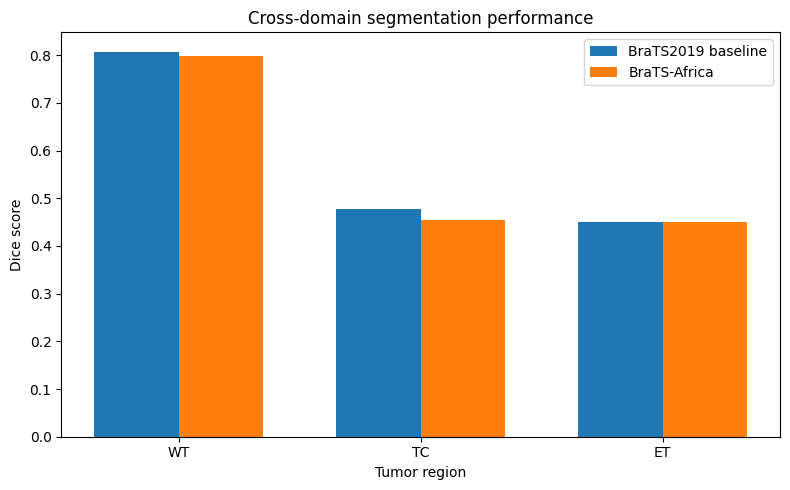

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

metrics = ["WT", "TC", "ET"]

baseline_means = [
    comparison_df["WT_Dice_Baseline2019"].mean(),
    comparison_df["TC_Dice_Baseline2019"].mean(),
    comparison_df["ET_Dice_Baseline2019"].mean()
]

africa_means = [
    comparison_df["WT_Dice_Africa"].mean(),
    comparison_df["TC_Dice_Africa"].mean(),
    comparison_df["ET_Dice_Africa"].mean()
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width/2,
    baseline_means,
    width,
    label="BraTS2019 baseline"
)

plt.bar(
    x + width/2,
    africa_means,
    width,
    label="BraTS-Africa"
)

plt.xticks(x, metrics)
plt.ylabel("Dice score")
plt.xlabel("Tumor region")
plt.title("Cross-domain segmentation performance")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
final_comparison_path = "/content/drive/MyDrive/Master_SIIA/final_model_comparison.csv"

comparison_df.to_csv(
    final_comparison_path,
    index=False
)

comparison_summary.to_csv(
    "/content/drive/MyDrive/Master_SIIA/comparison_summary.csv",
    index=False
)

print("Final results saved successfully ✅")
print(final_comparison_path)

Final results saved successfully ✅
/content/drive/MyDrive/Master_SIIA/final_model_comparison.csv


In [ ]:
def normalize_mri(image):
    mask = image > 0

    mean = np.mean(image[mask])
    std = np.std(image[mask])

    normalized = np.zeros_like(image, dtype=np.float32)
    normalized[mask] = (image[mask] - mean) / std

    return normalized

print("normalize_mri")

normalize_mri


In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv3d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet3D(nn.Module):
    def __init__(self, in_channels=4, out_channels=4):
        super().__init__()

        self.enc1 = DoubleConv(4, 16)
        self.pool1 = nn.MaxPool3d(2)

        self.enc2 = DoubleConv(16, 32)
        self.pool2 = nn.MaxPool3d(2)

        self.enc3 = DoubleConv(32, 64)
        self.pool3 = nn.MaxPool3d(2)

        self.bottleneck = DoubleConv(64, 128)

        self.up3 = nn.ConvTranspose3d(128, 64, 2, 2)
        self.dec3 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose3d(64, 32, 2, 2)
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose3d(32, 16, 2, 2)
        self.dec1 = DoubleConv(32, 16)

        self.final_conv = nn.Conv3d(16, 4, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        p1 = self.pool1(e1)

        e2 = self.enc2(p1)
        p2 = self.pool2(e2)

        e3 = self.enc3(p2)
        p3 = self.pool3(e3)

        b = self.bottleneck(p3)

        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final_conv(d1)


print("UNet3D")

UNet3D


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

baseline_model_path = (
    "/content/drive/MyDrive/Master_SIIA/"
    "checkpoints_BraTS2019/best_model.pth"
)

finetune_model = UNet3D(
    in_channels=4,
    out_channels=4
).to(device)

checkpoint = torch.load(
    baseline_model_path,
    map_location=device,
    weights_only=False
)

finetune_model.load_state_dict(
    checkpoint["model_state_dict"]
)

finetune_model.eval()

print("BraTS2019 model loaded successfully ✅")
print("Starting epoch:", checkpoint["epoch"])
print("Original validation Dice:", checkpoint["val_dice"])

BraTS2019 model loaded successfully ✅
Starting epoch: 10
Original validation Dice: 0.49672472819611535


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import nibabel as nib

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

print("Imports done ✅")
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Imports done ✅
PyTorch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4


In [ ]:
# BraTS-Africa dataset path
dataset_path = "/content/drive/MyDrive/Master_SIIA/BraTS-Africa"
glioma_path = os.path.join(dataset_path, "95_Glioma")

# Get all patient IDs
patients = sorted([
    p for p in os.listdir(glioma_path)
    if os.path.isdir(os.path.join(glioma_path, p))
])

# Reproduce the exact same split as before
random.seed(42)
random.shuffle(patients)

n = len(patients)
n_train = int(0.70 * n)
n_val = int(0.15 * n)

train_patients = patients[:n_train]
val_patients = patients[n_train:n_train+n_val]
test_patients = patients[n_train+n_val:]

print("Total patients:", len(patients))
print("Train:", len(train_patients))
print("Validation:", len(val_patients))
print("Test:", len(test_patients))

print("\nFirst train patients:", train_patients[:3])
print("First validation patients:", val_patients[:3])
print("First test patients:", test_patients[:3])

Total patients: 95
Train: 66
Validation: 14
Test: 15

First train patients: ['BraTS-SSA-00163-000', 'BraTS-SSA-00143-000', 'BraTS-SSA-00146-000']
First validation patients: ['BraTS-SSA-00056-000', 'BraTS-SSA-00002-000', 'BraTS-SSA-00226-000']
First test patients: ['BraTS-SSA-00227-000', 'BraTS-SSA-00011-000', 'BraTS-SSA-00137-000']


In [ ]:
# ==========================================
# BraTS-Africa Dataset for Fine-Tuning
# ==========================================

def normalize_mri(image):
    mask = image > 0

    mean = np.mean(image[mask])
    std = np.std(image[mask])

    normalized = np.zeros_like(image, dtype=np.float32)
    normalized[mask] = (image[mask] - mean) / std

    return normalized


class BraTSAfricaPatchDataset(Dataset):

    def __init__(self, patient_list, data_path, patch_size=(96, 96, 96)):
        self.patient_list = patient_list
        self.data_path = data_path
        self.patch_size = patch_size

        # Same semantic modality order as BraTS2019:
        # T1, T1CE, T2, FLAIR
        self.modalities = ["t1n", "t1c", "t2w", "t2f"]

    def __len__(self):
        return len(self.patient_list)

    def __getitem__(self, idx):

        patient_id = self.patient_list[idx]

        patient_path = os.path.join(
            self.data_path,
            patient_id
        )

        # -----------------------------
        # Load MRI modalities
        # -----------------------------
        images = []

        for modality in self.modalities:

            file_path = os.path.join(
                patient_path,
                f"{patient_id}-{modality}.nii.gz"
            )

            img = nib.load(file_path).get_fdata()

            img = normalize_mri(img)

            images.append(img.astype(np.float32))

        image = np.stack(images, axis=0)

        # -----------------------------
        # Load segmentation
        # -----------------------------
        seg_path = os.path.join(
            patient_path,
            f"{patient_id}-seg.nii.gz"
        )

        seg = nib.load(seg_path).get_fdata().astype(np.int64)

        # -----------------------------
        # Select random tumor voxel
        # -----------------------------
        tumor_voxels = np.argwhere(seg > 0)

        center = tumor_voxels[
            random.randint(0, len(tumor_voxels) - 1)
        ]

        # -----------------------------
        # Extract 96x96x96 patch
        # -----------------------------
        starts = []

        for i in range(3):

            start = (
                center[i]
                - self.patch_size[i] // 2
            )

            start = max(0, start)

            start = min(
                start,
                image.shape[i + 1] - self.patch_size[i]
            )

            starts.append(start)

        z, y, x = starts

        image_patch = image[
            :,
            z:z+self.patch_size[0],
            y:y+self.patch_size[1],
            x:x+self.patch_size[2]
        ]

        seg_patch = seg[
            z:z+self.patch_size[0],
            y:y+self.patch_size[1],
            x:x+self.patch_size[2]
        ]

        return (
            torch.from_numpy(image_patch),
            torch.from_numpy(seg_patch)
        )


print("BraTS-Africa fine-tuning Dataset class created ✅")

BraTS-Africa fine-tuning Dataset class created ✅


In [ ]:
# ==========================================
# Create Fine-Tuning Datasets
# ==========================================

patch_train_dataset = BraTSAfricaPatchDataset(
    train_patients,
    glioma_path,
    patch_size=(96, 96, 96)
)

patch_val_dataset = BraTSAfricaPatchDataset(
    val_patients,
    glioma_path,
    patch_size=(96, 96, 96)
)

print("Train dataset:", len(patch_train_dataset))
print("Validation dataset:", len(patch_val_dataset))

Train dataset: 66
Validation dataset: 14


In [ ]:
# ==========================================
# Fine-Tuning DataLoaders
# ==========================================

train_loader = DataLoader(
    patch_train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    patch_val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 66
Validation batches: 14


In [ ]:
# ==========================================
# Recreate 3D U-Net architecture
# ==========================================

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.conv = nn.Sequential(

            nn.Conv3d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm3d(out_channels),

            nn.ReLU(inplace=True),

            nn.Conv3d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm3d(out_channels),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        return self.conv(x)


class UNet3D(nn.Module):

    def __init__(
        self,
        in_channels=4,
        out_channels=4
    ):

        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(4, 16)
        self.pool1 = nn.MaxPool3d(2)

        self.enc2 = DoubleConv(16, 32)
        self.pool2 = nn.MaxPool3d(2)

        self.enc3 = DoubleConv(32, 64)
        self.pool3 = nn.MaxPool3d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(64, 128)

        # Decoder
        self.up3 = nn.ConvTranspose3d(
            128, 64, 2, 2
        )
        self.dec3 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose3d(
            64, 32, 2, 2
        )
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose3d(
            32, 16, 2, 2
        )
        self.dec1 = DoubleConv(32, 16)

        # Output
        self.final_conv = nn.Conv3d(
            16,
            4,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        p1 = self.pool1(e1)

        e2 = self.enc2(p1)
        p2 = self.pool2(e2)

        e3 = self.enc3(p2)
        p3 = self.pool3(e3)

        # Bottleneck
        b = self.bottleneck(p3)

        # Decoder
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final_conv(d1)


print("UNet3D architecture recreated successfully ✅")

UNet3D architecture recreated successfully ✅


In [ ]:
# ==========================================
# Load BraTS2019 pretrained weights
# ==========================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

baseline_model_path = (
    "/content/drive/MyDrive/Master_SIIA/"
    "checkpoints_BraTS2019/best_model.pth"
)

finetune_model = UNet3D(
    in_channels=4,
    out_channels=4
).to(device)

checkpoint = torch.load(
    baseline_model_path,
    map_location=device,
    weights_only=False
)

finetune_model.load_state_dict(
    checkpoint["model_state_dict"]
)

finetune_model.eval()

print("BraTS2019 pretrained model loaded successfully ✅")
print("Starting epoch:", checkpoint["epoch"])
print("Original validation Dice:", checkpoint["val_dice"])
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

BraTS2019 pretrained model loaded successfully ✅
Starting epoch: 10
Original validation Dice: 0.49672472819611535
Device: cuda
GPU: Tesla T4


In [ ]:
# ==========================================
# Fine-Tuning Loss
# ==========================================

def dice_loss(logits, targets, num_classes=4, smooth=1e-5):

    probs = F.softmax(logits, dim=1)

    targets_one_hot = F.one_hot(
        targets,
        num_classes=num_classes
    ).permute(0, 4, 1, 2, 3).float()

    dims = (0, 2, 3, 4)

    intersection = (
        probs * targets_one_hot
    ).sum(dims)

    denominator = (
        probs.sum(dims)
        + targets_one_hot.sum(dims)
    )

    dice = (
        2 * intersection + smooth
    ) / (
        denominator + smooth
    )

    # Ignore background class 0
    return 1 - dice[1:].mean()


criterion_ce = nn.CrossEntropyLoss()

def combined_loss(logits, targets):

    ce = criterion_ce(logits, targets)
    dl = dice_loss(logits, targets)

    return ce + dl


# ==========================================
# Fine-Tuning Optimizer
# ==========================================

optimizer = torch.optim.Adam(
    finetune_model.parameters(),
    lr=1e-5
)

print("Loss function created ✅")
print("Optimizer created ✅")
print("Learning rate:", 1e-5)

Loss function created ✅
Optimizer created ✅
Learning rate: 1e-05


In [ ]:
# ==========================================
# Fine-Tuning - Epoch 1
# ==========================================

finetune_model.train()

running_loss = 0.0

for batch_idx, (images, masks) in enumerate(train_loader):

    images = images.to(device)
    masks = masks.to(device)

    optimizer.zero_grad()

    outputs = finetune_model(images)

    loss = combined_loss(outputs, masks)

    loss.backward()

    optimizer.step()

    running_loss += loss.item()

    if (batch_idx + 1) % 10 == 0:
        print(
            f"Batch {batch_idx + 1}/{len(train_loader)} "
            f"- Loss: {loss.item():.4f}"
        )

avg_train_loss = running_loss / len(train_loader)

print("\nEpoch 1 completed ✅")
print(f"Average Train Loss: {avg_train_loss:.4f}")

Batch 10/66 - Loss: 1.3278
Batch 20/66 - Loss: 1.3742
Batch 30/66 - Loss: 1.4520
Batch 40/66 - Loss: 1.6846
Batch 50/66 - Loss: 1.4950
Batch 60/66 - Loss: 1.4509

Epoch 1 completed ✅
Average Train Loss: 1.4843


In [ ]:
# ==========================================
# Fine-Tuning - Validation after Epoch 1
# ==========================================

finetune_model.eval()

val_loss = 0.0
val_dice_scores = []

with torch.no_grad():

    for batch_idx, (images, masks) in enumerate(val_loader):

        images = images.to(device)
        masks = masks.to(device)

        outputs = finetune_model(images)

        loss = combined_loss(outputs, masks)

        val_loss += loss.item()

        # -----------------------------
        # Calculate Dice
        # -----------------------------
        predictions = torch.argmax(outputs, dim=1)

        dice_per_class = []

        for class_id in range(1, 4):

            pred_mask = (predictions == class_id).float()
            true_mask = (masks == class_id).float()

            intersection = (
                pred_mask * true_mask
            ).sum()

            denominator = (
                pred_mask.sum()
                + true_mask.sum()
            )

            dice = (
                (2 * intersection + 1e-5)
                / (denominator + 1e-5)
            )

            dice_per_class.append(dice.item())

        mean_dice = np.mean(dice_per_class)

        val_dice_scores.append(mean_dice)


avg_val_loss = val_loss / len(val_loader)
avg_val_dice = np.mean(val_dice_scores)

print("Validation completed ✅")
print(f"Validation Loss: {avg_val_loss:.4f}")
print(f"Validation Dice: {avg_val_dice:.4f}")

Validation completed ✅
Validation Loss: 1.4147
Validation Dice: 0.5889


In [ ]:
# ==========================================
# Fine-Tuning: Epochs 2 → 10
# ==========================================

num_total_epochs = 10

# Checkpoint directory
finetune_checkpoint_dir = (
    "/content/drive/MyDrive/Master_SIIA/"
    "checkpoints_finetune_BraTS_Africa"
)

os.makedirs(finetune_checkpoint_dir, exist_ok=True)

# Epoch 1 results obtained previously
best_val_dice = 0.5889

training_history = [
    {
        "epoch": 1,
        "train_loss": 1.4843,
        "val_loss": 1.4147,
        "val_dice": 0.5889
    }
]

for epoch in range(2, num_total_epochs + 1):

    # ======================================
    # TRAIN
    # ======================================

    finetune_model.train()

    running_train_loss = 0.0

    for batch_idx, (images, masks) in enumerate(train_loader):

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = finetune_model(images)

        loss = combined_loss(outputs, masks)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    avg_train_loss = (
        running_train_loss / len(train_loader)
    )

    # ======================================
    # VALIDATION
    # ======================================

    finetune_model.eval()

    running_val_loss = 0.0
    val_dice_scores = []

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = finetune_model(images)

            loss = combined_loss(outputs, masks)

            running_val_loss += loss.item()

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            dice_per_class = []

            for class_id in range(1, 4):

                pred_mask = (
                    predictions == class_id
                ).float()

                true_mask = (
                    masks == class_id
                ).float()

                intersection = (
                    pred_mask * true_mask
                ).sum()

                denominator = (
                    pred_mask.sum()
                    + true_mask.sum()
                )

                dice = (
                    (2 * intersection + 1e-5)
                    / (denominator + 1e-5)
                )

                dice_per_class.append(
                    dice.item()
                )

            mean_dice = np.mean(
                dice_per_class
            )

            val_dice_scores.append(
                mean_dice
            )

    avg_val_loss = (
        running_val_loss / len(val_loader)
    )

    avg_val_dice = np.mean(
        val_dice_scores
    )

    # ======================================
    # SAVE HISTORY
    # ======================================

    training_history.append({
        "epoch": epoch,
        "train_loss": avg_train_loss,
        "val_loss": avg_val_loss,
        "val_dice": avg_val_dice
    })

    # ======================================
    # SAVE CHECKPOINT
    # ======================================

    checkpoint_path = os.path.join(
        finetune_checkpoint_dir,
        f"checkpoint_epoch_{epoch}.pth"
    )

    torch.save({
        "epoch": epoch,
        "model_state_dict": finetune_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_loss": avg_train_loss,
        "val_loss": avg_val_loss,
        "val_dice": avg_val_dice
    }, checkpoint_path)

    # ======================================
    # SAVE BEST MODEL
    # ======================================

    if avg_val_dice > best_val_dice:

        best_val_dice = avg_val_dice

        best_model_path = os.path.join(
            finetune_checkpoint_dir,
            "best_model.pth"
        )

        torch.save({
            "epoch": epoch,
            "model_state_dict": finetune_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": avg_train_loss,
            "val_loss": avg_val_loss,
            "val_dice": avg_val_dice
        }, best_model_path)

        best_marker = " ⭐ BEST"
    else:
        best_marker = ""

    # ======================================
    # PRINT RESULTS
    # ======================================

    print(
        f"Epoch {epoch}/10 | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Dice: {avg_val_dice:.4f}"
        f"{best_marker}"
    )

print("\n==========================================")
print("Fine-tuning completed ✅")
print("==========================================")
print(f"Best Validation Dice: {best_val_dice:.4f}")
print(
    "Checkpoint directory:",
    finetune_checkpoint_dir
)

Epoch 2/10 | Train Loss: 1.4644 | Val Loss: 1.4241 | Val Dice: 0.5840
Epoch 3/10 | Train Loss: 1.4562 | Val Loss: 1.4145 | Val Dice: 0.5858
Epoch 4/10 | Train Loss: 1.4424 | Val Loss: 1.3998 | Val Dice: 0.5846
Epoch 5/10 | Train Loss: 1.4360 | Val Loss: 1.4247 | Val Dice: 0.5871
Epoch 6/10 | Train Loss: 1.4258 | Val Loss: 1.3941 | Val Dice: 0.6085 ⭐ BEST
Epoch 7/10 | Train Loss: 1.4234 | Val Loss: 1.3805 | Val Dice: 0.5950
Epoch 8/10 | Train Loss: 1.4190 | Val Loss: 1.3952 | Val Dice: 0.5526
Epoch 9/10 | Train Loss: 1.4088 | Val Loss: 1.3933 | Val Dice: 0.5487
Epoch 10/10 | Train Loss: 1.4005 | Val Loss: 1.3950 | Val Dice: 0.5532

Fine-tuning completed ✅
Best Validation Dice: 0.6085
Checkpoint directory: /content/drive/MyDrive/Master_SIIA/checkpoints_finetune_BraTS_Africa


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import nibabel as nib

import torch
import torch.nn as nn
import torch.nn.functional as F

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA: True
GPU: Tesla T4


In [ ]:
class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv3d(
                in_channels,
                out_channels,
                3,
                padding=1
            ),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv3d(
                out_channels,
                out_channels,
                3,
                padding=1
            ),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet3D(nn.Module):

    def __init__(self, in_channels=4, out_channels=4):
        super().__init__()

        self.enc1 = DoubleConv(4, 16)
        self.pool1 = nn.MaxPool3d(2)

        self.enc2 = DoubleConv(16, 32)
        self.pool2 = nn.MaxPool3d(2)

        self.enc3 = DoubleConv(32, 64)
        self.pool3 = nn.MaxPool3d(2)

        self.bottleneck = DoubleConv(64, 128)

        self.up3 = nn.ConvTranspose3d(128, 64, 2, 2)
        self.dec3 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose3d(64, 32, 2, 2)
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose3d(32, 16, 2, 2)
        self.dec1 = DoubleConv(32, 16)

        self.final_conv = nn.Conv3d(16, 4, 1)

    def forward(self, x):

        e1 = self.enc1(x)
        p1 = self.pool1(e1)

        e2 = self.enc2(p1)
        p2 = self.pool2(e2)

        e3 = self.enc3(p2)
        p3 = self.pool3(e3)

        b = self.bottleneck(p3)

        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final_conv(d1)


print("UNet3D recreated successfully ✅")

UNet3D recreated successfully ✅


In [ ]:
dataset_path = "/content/drive/MyDrive/Master_SIIA/BraTS-Africa"
glioma_path = os.path.join(dataset_path, "95_Glioma")

patients = sorted([
    p for p in os.listdir(glioma_path)
    if os.path.isdir(os.path.join(glioma_path, p))
])

# Exact same split used before
random.seed(42)
random.shuffle(patients)

n = len(patients)
n_train = int(0.70 * n)
n_val = int(0.15 * n)

train_patients = patients[:n_train]
val_patients = patients[n_train:n_train+n_val]
test_patients = patients[n_train+n_val:]

print("Total:", len(patients))
print("Train:", len(train_patients))
print("Validation:", len(val_patients))
print("Test:", len(test_patients))

print("\nTest patients:")
print(test_patients)

Total: 95
Train: 66
Validation: 14
Test: 15

Test patients:
['BraTS-SSA-00227-000', 'BraTS-SSA-00011-000', 'BraTS-SSA-00137-000', 'BraTS-SSA-00179-000', 'BraTS-SSA-00037-000', 'BraTS-SSA-00161-000', 'BraTS-SSA-00218-000', 'BraTS-SSA-00044-000', 'BraTS-SSA-00050-000', 'BraTS-SSA-00092-000', 'BraTS-SSA-00096-000', 'BraTS-SSA-00113-000', 'BraTS-SSA-00010-000', 'BraTS-SSA-00046-000', 'BraTS-SSA-00206-000']


In [ ]:
finetune_model_path = (
    "/content/drive/MyDrive/Master_SIIA/"
    "checkpoints_finetune_BraTS_Africa/"
    "best_model.pth"
)

finetune_model = UNet3D(
    in_channels=4,
    out_channels=4
).to(device)

checkpoint = torch.load(
    finetune_model_path,
    map_location=device,
    weights_only=False
)

finetune_model.load_state_dict(
    checkpoint["model_state_dict"]
)

finetune_model.eval()

print("Fine-tuned model loaded successfully ✅")
print("Best epoch:", checkpoint["epoch"])
print("Best validation Dice:", checkpoint["val_dice"])

Fine-tuned model loaded successfully ✅
Best epoch: 6
Best validation Dice: 0.6085158248919823


In [ ]:
def normalize_mri(image):

    mask = image > 0

    mean = np.mean(image[mask])
    std = np.std(image[mask])

    normalized = np.zeros_like(
        image,
        dtype=np.float32
    )

    normalized[mask] = (
        image[mask] - mean
    ) / std

    return normalized


print("Normalization function ready ✅")

Normalization function ready ✅


In [ ]:
def predict_full_volume(
    model,
    patient_id,
    data_path,
    patch_size=(96, 96, 96),
    stride=64
):

    patient_path = os.path.join(
        data_path,
        patient_id
    )

    modalities = [
        "t1n",
        "t1c",
        "t2w",
        "t2f"
    ]

    images = []

    for modality in modalities:

        file_path = os.path.join(
            patient_path,
            f"{patient_id}-{modality}.nii.gz"
        )

        img = nib.load(file_path).get_fdata()

        img = normalize_mri(img)

        images.append(
            img.astype(np.float32)
        )

    image = np.stack(images, axis=0)

    # Ground-truth segmentation
    seg_path = os.path.join(
        patient_path,
        f"{patient_id}-seg.nii.gz"
    )

    seg = nib.load(seg_path).get_fdata().astype(
        np.int64
    )

    D, H, W = image.shape[1:]

    pdim, ph, pw = patch_size

    probability_sum = np.zeros(
        (4, D, H, W),
        dtype=np.float32
    )

    count_map = np.zeros(
        (D, H, W),
        dtype=np.float32
    )

    model.eval()

    with torch.no_grad():

        for z in range(0, D - pdim + 1, stride):

            for y in range(0, H - ph + 1, stride):

                for x in range(0, W - pw + 1, stride):

                    patch = image[
                        :,
                        z:z+pdim,
                        y:y+ph,
                        x:x+pw
                    ]

                    patch_tensor = torch.from_numpy(
                        patch
                    ).unsqueeze(0).to(device)

                    logits = model(patch_tensor)

                    probs = F.softmax(
                        logits,
                        dim=1
                    )[0].cpu().numpy()

                    probability_sum[
                        :,
                        z:z+pdim,
                        y:y+ph,
                        x:x+pw
                    ] += probs

                    count_map[
                        z:z+pdim,
                        y:y+ph,
                        x:x+pw
                    ] += 1

    # Average overlapping predictions
    probability_sum /= np.maximum(
        count_map[None, ...],
        1e-8
    )

    prediction = np.argmax(
        probability_sum,
        axis=0
    )

    return prediction, seg


print("Full-volume inference function ready ✅")

Full-volume inference function ready ✅


In [ ]:
def calculate_dice(pred, true, region):

    pred_mask = region(pred)
    true_mask = region(true)

    intersection = np.logical_and(
        pred_mask,
        true_mask
    ).sum()

    denominator = (
        pred_mask.sum()
        + true_mask.sum()
    )

    if denominator == 0:
        return 1.0

    return (
        2.0 * intersection
        / denominator
    )


def calculate_regions_dice(pred, true):

    wt_dice = calculate_dice(
        pred,
        true,
        lambda x: x > 0
    )

    tc_dice = calculate_dice(
        pred,
        true,
        lambda x: (x == 1) | (x == 3)
    )

    et_dice = calculate_dice(
        pred,
        true,
        lambda x: x == 3
    )

    return wt_dice, tc_dice, et_dice


print("Dice functions ready ✅")

Dice functions ready ✅


In [ ]:
# ==========================================
# Full-volume evaluation
# Fine-tuned model
# ==========================================

finetune_results = []

for i, patient_id in enumerate(test_patients):

    print(
        f"[{i+1}/{len(test_patients)}] "
        f"Processing {patient_id}..."
    )

    prediction, ground_truth = predict_full_volume(
        finetune_model,
        patient_id,
        glioma_path,
        patch_size=(96, 96, 96),
        stride=64
    )

    wt_dice, tc_dice, et_dice = (
        calculate_regions_dice(
            prediction,
            ground_truth
        )
    )

    finetune_results.append({
        "patient_id": patient_id,
        "WT_Dice": wt_dice,
        "TC_Dice": tc_dice,
        "ET_Dice": et_dice
    })

    print(
        f"   WT: {wt_dice:.4f} | "
        f"TC: {tc_dice:.4f} | "
        f"ET: {et_dice:.4f}"
    )

finetune_df = pd.DataFrame(
    finetune_results
)

print("\nFine-tuned model evaluation completed ✅")

print("\nMean Dice:")
print(
    "WT:",
    finetune_df["WT_Dice"].mean()
)
print(
    "TC:",
    finetune_df["TC_Dice"].mean()
)
print(
    "ET:",
    finetune_df["ET_Dice"].mean()
)

[1/15] Processing BraTS-SSA-00227-000...
   WT: 0.0000 | TC: 0.0000 | ET: 0.0000
[2/15] Processing BraTS-SSA-00011-000...
   WT: 0.3990 | TC: 0.0455 | ET: 0.0777
[3/15] Processing BraTS-SSA-00137-000...
   WT: 0.2825 | TC: 0.2279 | ET: 0.2314
[4/15] Processing BraTS-SSA-00179-000...
   WT: 0.5434 | TC: 0.2947 | ET: 0.3424
[5/15] Processing BraTS-SSA-00037-000...
   WT: 0.9219 | TC: 0.5487 | ET: 0.8084
[6/15] Processing BraTS-SSA-00161-000...
   WT: 0.3582 | TC: 0.2854 | ET: 0.3274
[7/15] Processing BraTS-SSA-00218-000...
   WT: 0.8908 | TC: 0.9081 | ET: 0.8652
[8/15] Processing BraTS-SSA-00044-000...
   WT: 0.6816 | TC: 0.5406 | ET: 0.6127
[9/15] Processing BraTS-SSA-00050-000...
   WT: 0.5046 | TC: 0.4423 | ET: 0.4895
[10/15] Processing BraTS-SSA-00092-000...
   WT: 0.6451 | TC: 0.0625 | ET: 0.0000
[11/15] Processing BraTS-SSA-00096-000...
   WT: 0.8805 | TC: 0.1023 | ET: 0.3970
[12/15] Processing BraTS-SSA-00113-000...
   WT: 0.6140 | TC: 0.6786 | ET: 0.1308
[13/15] Processing BraTS-

In [ ]:
finetune_results_path = (
    "/content/drive/MyDrive/Master_SIIA/"
    "finetuned_model_on_africa_test.csv"
)

finetune_df.to_csv(
    finetune_results_path,
    index=False
)

print(
    "Results saved successfully ✅"
)
print(finetune_results_path)

Results saved successfully ✅
/content/drive/MyDrive/Master_SIIA/finetuned_model_on_africa_test.csv


In [ ]:
# ==========================================
# FINAL MODEL COMPARISON
# ==========================================

import pandas as pd
import numpy as np

# Paths
baseline_path = (
    "/content/drive/MyDrive/Master_SIIA/"
    "brats2019_baseline_on_africa_test.csv"
)

africa_path = (
    "/content/drive/MyDrive/Master_SIIA/"
    "full_volume_test_results.csv"
)

finetune_path = (
    "/content/drive/MyDrive/Master_SIIA/"
    "finetuned_model_on_africa_test.csv"
)

# Load results
baseline_df = pd.read_csv(baseline_path)
africa_df = pd.read_csv(africa_path)
finetune_df = pd.read_csv(finetune_path)

# Make patient column names consistent
africa_df = africa_df.rename(
    columns={"patient": "patient_id"}
)

# Add model names
baseline_df["Model"] = "BraTS2019 Baseline"
africa_df["Model"] = "BraTS-Africa From Scratch"
finetune_df["Model"] = "BraTS2019 + Africa Fine-Tuning"

# Combine
comparison_df = pd.concat(
    [
        baseline_df,
        africa_df,
        finetune_df
    ],
    ignore_index=True
)

# Summary
summary = comparison_df.groupby("Model")[
    ["WT_Dice", "TC_Dice", "ET_Dice"]
].agg(["mean", "std"])

print("FINAL RESULTS")
print("=" * 70)

for model in comparison_df["Model"].unique():

    df = comparison_df[
        comparison_df["Model"] == model
    ]

    print(f"\n{model}")

    print(
        f"WT: {df['WT_Dice'].mean():.4f} "
        f"± {df['WT_Dice'].std():.4f}"
    )

    print(
        f"TC: {df['TC_Dice'].mean():.4f} "
        f"± {df['TC_Dice'].std():.4f}"
    )

    print(
        f"ET: {df['ET_Dice'].mean():.4f} "
        f"± {df['ET_Dice'].std():.4f}"
    )

# Save
summary_path = (
    "/content/drive/MyDrive/Master_SIIA/"
    "final_three_model_comparison.csv"
)

summary.to_csv(summary_path)

print("\nSaved ✅")
print(summary_path)

FINAL RESULTS

BraTS2019 Baseline
WT: 0.8076 ± 0.2365
TC: 0.4776 ± 0.3188
ET: 0.4512 ± 0.2790

BraTS-Africa From Scratch
WT: 0.7975 ± 0.2503
TC: 0.4549 ± 0.3273
ET: 0.4496 ± 0.2846

BraTS2019 + Africa Fine-Tuning
WT: 0.6104 ± 0.2666
TC: 0.3806 ± 0.3106
ET: 0.3792 ± 0.3032

Saved ✅
/content/drive/MyDrive/Master_SIIA/final_three_model_comparison.csv


In [ ]:
import pandas as pd
import numpy as np
import os

base_path = "/content/drive/MyDrive/Master_SIIA"

baseline_file = os.path.join(
    base_path, "brats2019_baseline_on_africa_test.csv"
)

africa_file = os.path.join(
    base_path, "full_volume_test_results.csv"
)

finetune_file = os.path.join(
    base_path, "finetuned_model_on_africa_test.csv"
)

baseline_df = pd.read_csv(baseline_file)
africa_df = pd.read_csv(africa_file)
finetune_df = pd.read_csv(finetune_file)

print("Baseline:")
display(baseline_df.head())

print("\nAfrica:")
display(africa_df.head())

print("\nFine-tuning:")
display(finetune_df.head())

Baseline:


,patient_id,WT_Dice,TC_Dice,ET_Dice
0,BraTS-SSA-00227-000,2.454590e-09,8.467400e-09,1.477105e-08
1,BraTS-SSA-00011-000,9.524608e-01,6.327137e-01,5.378995e-01
2,BraTS-SSA-00137-000,9.275853e-01,5.234852e-01,8.889224e-01
3,BraTS-SSA-00179-000,9.149311e-01,8.330401e-01,5.265435e-01
4,BraTS-SSA-00037-000,8.772631e-01,2.263406e-01,6.360029e-01



Africa:


,patient,WT_Dice,TC_Dice,ET_Dice
0,BraTS-SSA-00227-000,0.010891,0.000000,0.000000
1,BraTS-SSA-00011-000,0.930677,0.734342,0.612415
2,BraTS-SSA-00137-000,0.928856,0.835058,0.825526
3,BraTS-SSA-00179-000,0.911890,0.821836,0.696112
4,BraTS-SSA-00037-000,0.889978,0.439859,0.418097



Fine-tuning:


,patient_id,WT_Dice,TC_Dice,ET_Dice
0,BraTS-SSA-00227-000,0.000000,0.000000,0.000000
1,BraTS-SSA-00011-000,0.398987,0.045525,0.077664
2,BraTS-SSA-00137-000,0.282475,0.227876,0.231421
3,BraTS-SSA-00179-000,0.543433,0.294669,0.342441
4,BraTS-SSA-00037-000,0.921853,0.548696,0.808427


In [ ]:
print("Baseline columns:")
print(baseline_df.columns.tolist())

print("\nAfrica columns:")
print(africa_df.columns.tolist())

print("\nFine-tuning columns:")
print(finetune_df.columns.tolist())

Baseline columns:
['patient_id', 'WT_Dice', 'TC_Dice', 'ET_Dice']

Africa columns:
['patient', 'WT_Dice', 'TC_Dice', 'ET_Dice']

Fine-tuning columns:
['patient_id', 'WT_Dice', 'TC_Dice', 'ET_Dice']


In [ ]:
# Garder uniquement les colonnes nécessaires
baseline_results = baseline_df[["patient_id", "WT_Dice", "TC_Dice", "ET_Dice"]].copy()
africa_results = africa_df[["patient", "WT_Dice", "TC_Dice", "ET_Dice"]].copy()
finetune_results = finetune_df[["patient_id", "WT_Dice", "TC_Dice", "ET_Dice"]].copy()

# Ajouter le nom du modèle
baseline_results["Model"] = "BraTS2019 Baseline"
africa_results["Model"] = "BraTS-Africa From Scratch"
finetune_results["Model"] = "BraTS2019 + Africa Fine-Tuning"

# Combiner
all_results = pd.concat(
    [baseline_results, africa_results, finetune_results],
    ignore_index=True
)

print("Number of rows:", len(all_results))
display(all_results.head(10))

Number of rows: 45


,patient_id,WT_Dice,TC_Dice,ET_Dice,Model,patient
0,BraTS-SSA-00227-000,2.454590e-09,8.467400e-09,1.477105e-08,BraTS2019 Baseline,NaN
1,BraTS-SSA-00011-000,9.524608e-01,6.327137e-01,5.378995e-01,BraTS2019 Baseline,NaN
2,BraTS-SSA-00137-000,9.275853e-01,5.234852e-01,8.889224e-01,BraTS2019 Baseline,NaN
3,BraTS-SSA-00179-000,9.149311e-01,8.330401e-01,5.265435e-01,BraTS2019 Baseline,NaN
4,BraTS-SSA-00037-000,8.772631e-01,2.263406e-01,6.360029e-01,BraTS2019 Baseline,NaN
5,BraTS-SSA-00161-000,7.564723e-01,7.771878e-01,6.066958e-01,BraTS2019 Baseline,NaN
6,BraTS-SSA-00218-000,8.528900e-01,7.761713e-01,7.775721e-01,BraTS2019 Baseline,NaN
7,BraTS-SSA-00044-000,8.464425e-01,3.253822e-01,5.334145e-01,BraTS2019 Baseline,NaN
8,BraTS-SSA-00050-000,9.053113e-01,8.367669e-02,2.575777e-01,BraTS2019 Baseline,NaN
9,BraTS-SSA-00092-000,7.089513e-01,9.516516e-02,9.389671e-09,BraTS2019 Baseline,NaN


In [ ]:
baseline_patients = set(baseline_results["patient_id"])
africa_patients = set(africa_results["patient"])
finetune_patients = set(finetune_results["patient_id"])

print("Baseline patients:", len(baseline_patients))
print("Africa patients:", len(africa_patients))
print("Fine-tuning patients:", len(finetune_patients))

print("\nSame patients?")
print("Baseline == Africa:", baseline_patients == africa_patients)
print("Baseline == Fine-tuning:", baseline_patients == finetune_patients)
print("Africa == Fine-tuning:", africa_patients == finetune_patients)

print("\nCommon patients:", len(
    baseline_patients & africa_patients & finetune_patients
))

Baseline patients: 15
Africa patients: 15
Fine-tuning patients: 15

Same patients?
Baseline == Africa: True
Baseline == Fine-tuning: True
Africa == Fine-tuning: True

Common patients: 15


In [ ]:
metrics = ["WT_Dice", "TC_Dice", "ET_Dice"]

summary = []

for model_name, group in all_results.groupby("Model"):
    row = {"Model": model_name}

    for metric in metrics:
        mean = group[metric].mean()
        std = group[metric].std()

        row[metric] = f"{mean:.4f} ± {std:.4f}"

    summary.append(row)

summary_df = pd.DataFrame(summary)

display(summary_df)

,Model,WT_Dice,TC_Dice,ET_Dice
0,BraTS-Africa From Scratch,0.7975 ± 0.2503,0.4549 ± 0.3273,0.4496 ± 0.2846
1,BraTS2019 + Africa Fine-Tuning,0.6104 ± 0.2666,0.3806 ± 0.3106,0.3792 ± 0.3032
2,BraTS2019 Baseline,0.8076 ± 0.2365,0.4776 ± 0.3188,0.4512 ± 0.2790


In [ ]:
summary_file = os.path.join(
    base_path,
    "final_summary_mean_std.csv"
)

summary_df.to_csv(summary_file, index=False)

print("Saved:", summary_file)

Saved: /content/drive/MyDrive/Master_SIIA/final_summary_mean_std.csv


In [ ]:
mean_table = all_results.groupby("Model")[metrics].mean()

baseline_mean = mean_table.loc["BraTS2019 Baseline"]
africa_mean = mean_table.loc["BraTS-Africa From Scratch"]
finetune_mean = mean_table.loc["BraTS2019 + Africa Fine-Tuning"]

difference_table = pd.DataFrame({
    "Africa - Baseline": africa_mean - baseline_mean,
    "Fine-tuning - Baseline": finetune_mean - baseline_mean
})

display(difference_table)

,Africa - Baseline,Fine-tuning - Baseline
WT_Dice,-0.010059,-0.197160
TC_Dice,-0.022622,-0.097012
ET_Dice,-0.001623,-0.072002


In [ ]:
percentage_change = pd.DataFrame({
    "Africa vs Baseline (%)":
        ((africa_mean - baseline_mean) / baseline_mean) * 100,

    "Fine-tuning vs Baseline (%)":
        ((finetune_mean - baseline_mean) / baseline_mean) * 100
})

display(percentage_change)

,Africa vs Baseline (%),Fine-tuning vs Baseline (%)
WT_Dice,-1.245580,-24.414196
TC_Dice,-4.736945,-20.313851
ET_Dice,-0.359637,-15.957268


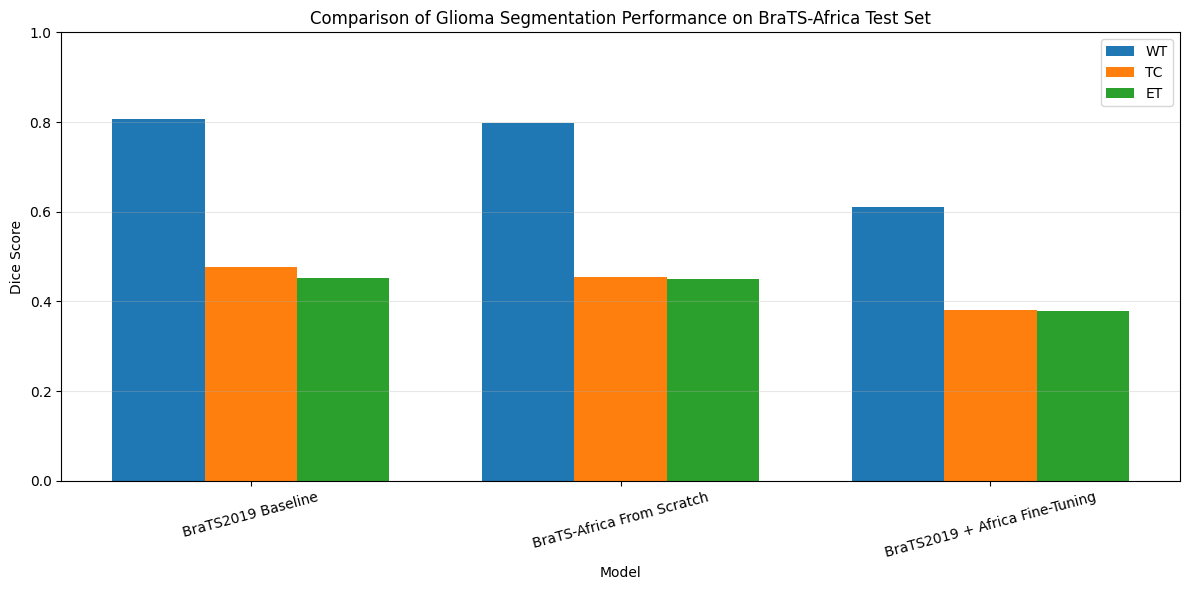

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = [
    "BraTS2019 Baseline",
    "BraTS-Africa From Scratch",
    "BraTS2019 + Africa Fine-Tuning"
]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(
    x - width,
    mean_table.loc[models, "WT_Dice"],
    width,
    label="WT"
)

plt.bar(
    x,
    mean_table.loc[models, "TC_Dice"],
    width,
    label="TC"
)

plt.bar(
    x + width,
    mean_table.loc[models, "ET_Dice"],
    width,
    label="ET"
)

plt.ylabel("Dice Score")
plt.xlabel("Model")
plt.title("Comparison of Glioma Segmentation Performance on BraTS-Africa Test Set")

plt.xticks(x, models, rotation=15)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

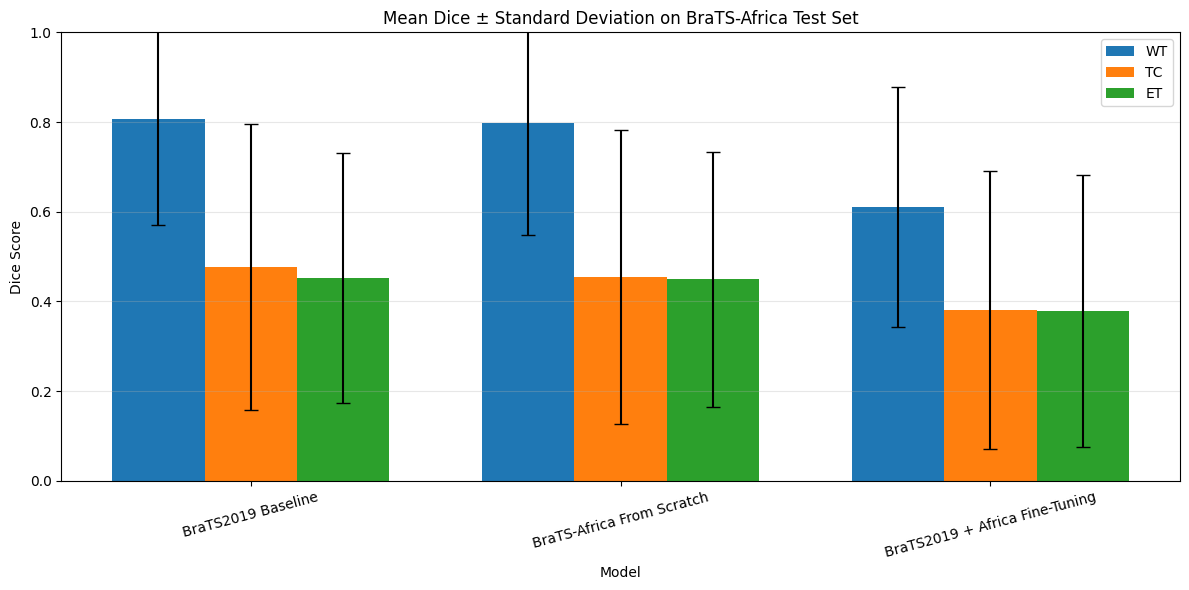

In [ ]:
mean_values = all_results.groupby("Model")[metrics].mean().loc[models]
std_values = all_results.groupby("Model")[metrics].std().loc[models]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(
    x - width,
    mean_values["WT_Dice"],
    width,
    yerr=std_values["WT_Dice"],
    capsize=5,
    label="WT"
)

plt.bar(
    x,
    mean_values["TC_Dice"],
    width,
    yerr=std_values["TC_Dice"],
    capsize=5,
    label="TC"
)

plt.bar(
    x + width,
    mean_values["ET_Dice"],
    width,
    yerr=std_values["ET_Dice"],
    capsize=5,
    label="ET"
)

plt.ylabel("Dice Score")
plt.xlabel("Model")
plt.title("Mean Dice ± Standard Deviation on BraTS-Africa Test Set")

plt.xticks(x, models, rotation=15)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
africa_results = africa_results.rename(columns={"patient": "patient_id"})

patient_comparison = baseline_results.merge(
    africa_results,
    on="patient_id",
    suffixes=("_baseline", "_africa")
)

patient_comparison = patient_comparison.merge(
    finetune_results,
    on="patient_id"
)

patient_comparison = patient_comparison.rename(columns={
    "WT_Dice": "WT_Dice_finetune",
    "TC_Dice": "TC_Dice_finetune",
    "ET_Dice": "ET_Dice_finetune"
})

display(patient_comparison)

,patient_id,WT_Dice_baseline,TC_Dice_baseline,ET_Dice_baseline,Model_baseline,WT_Dice_africa,TC_Dice_africa,ET_Dice_africa,Model_africa,WT_Dice_finetune,TC_Dice_finetune,ET_Dice_finetune,Model
0,BraTS-SSA-00227-000,2.454590e-09,8.467400e-09,1.477105e-08,BraTS2019 Baseline,0.010891,0.000000,0.000000,BraTS-Africa From Scratch,0.000000,0.000000,0.000000,BraTS2019 + Africa Fine-Tuning
1,BraTS-SSA-00011-000,9.524608e-01,6.327137e-01,5.378995e-01,BraTS2019 Baseline,0.930677,0.734342,0.612415,BraTS-Africa From Scratch,0.398987,0.045525,0.077664,BraTS2019 + Africa Fine-Tuning
2,BraTS-SSA-00137-000,9.275853e-01,5.234852e-01,8.889224e-01,BraTS2019 Baseline,0.928856,0.835058,0.825526,BraTS-Africa From Scratch,0.282475,0.227876,0.231421,BraTS2019 + Africa Fine-Tuning
3,BraTS-SSA-00179-000,9.149311e-01,8.330401e-01,5.265435e-01,BraTS2019 Baseline,0.911890,0.821836,0.696112,BraTS-Africa From Scratch,0.543433,0.294669,0.342441,BraTS2019 + Africa Fine-Tuning
4,BraTS-SSA-00037-000,8.772631e-01,2.263406e-01,6.360029e-01,BraTS2019 Baseline,0.889978,0.439859,0.418097,BraTS-Africa From Scratch,0.921853,0.548696,0.808427,BraTS2019 + Africa Fine-Tuning
5,BraTS-SSA-00161-000,7.564723e-01,7.771878e-01,6.066958e-01,BraTS2019 Baseline,0.696630,0.492966,0.640474,BraTS-Africa From Scratch,0.358226,0.285435,0.327440,BraTS2019 + Africa Fine-Tuning
6,BraTS-SSA-00218-000,8.528900e-01,7.761713e-01,7.775721e-01,BraTS2019 Baseline,0.894716,0.889541,0.751106,BraTS-Africa From Scratch,0.890773,0.908075,0.865242,BraTS2019 + Africa Fine-Tuning
7,BraTS-SSA-00044-000,8.464425e-01,3.253822e-01,5.334145e-01,BraTS2019 Baseline,0.830989,0.407924,0.303140,BraTS-Africa From Scratch,0.681570,0.540578,0.612714,BraTS2019 + Africa Fine-Tuning
8,BraTS-SSA-00050-000,9.053113e-01,8.367669e-02,2.575777e-01,BraTS2019 Baseline,0.907160,0.168087,0.163079,BraTS-Africa From Scratch,0.504649,0.442347,0.489527,BraTS2019 + Africa Fine-Tuning
9,BraTS-SSA-00092-000,7.089513e-01,9.516516e-02,9.389671e-09,BraTS2019 Baseline,0.469280,0.002706,0.003830,BraTS-Africa From Scratch,0.645056,0.062498,0.000000,BraTS2019 + Africa Fine-Tuning


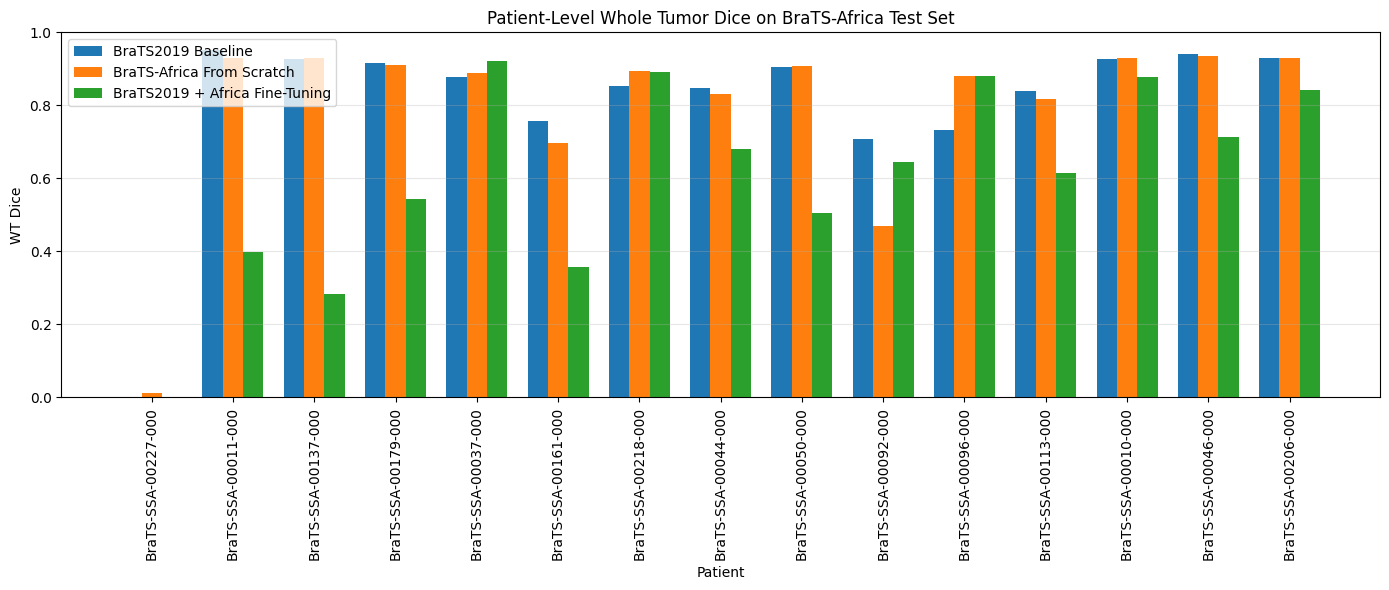

In [ ]:
plt.figure(figsize=(14, 6))

patients = patient_comparison["patient_id"]

x = np.arange(len(patients))
width = 0.25

plt.bar(
    x - width,
    patient_comparison["WT_Dice_baseline"],
    width,
    label="BraTS2019 Baseline"
)

plt.bar(
    x,
    patient_comparison["WT_Dice_africa"],
    width,
    label="BraTS-Africa From Scratch"
)

plt.bar(
    x + width,
    patient_comparison["WT_Dice_finetune"],
    width,
    label="BraTS2019 + Africa Fine-Tuning"
)

plt.xlabel("Patient")
plt.ylabel("WT Dice")
plt.title("Patient-Level Whole Tumor Dice on BraTS-Africa Test Set")

plt.xticks(x, patients, rotation=90)
plt.ylim(0, 1)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

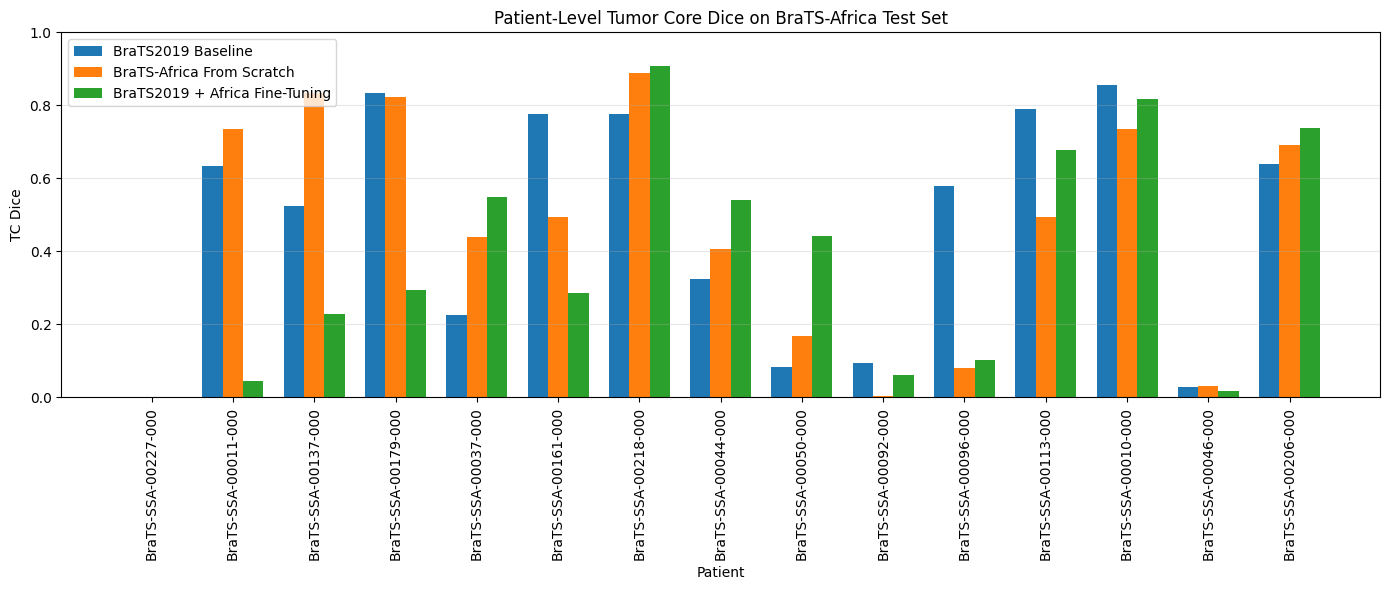

In [ ]:
plt.figure(figsize=(14, 6))

x = np.arange(len(patients))
width = 0.25

plt.bar(
    x - width,
    patient_comparison["TC_Dice_baseline"],
    width,
    label="BraTS2019 Baseline"
)

plt.bar(
    x,
    patient_comparison["TC_Dice_africa"],
    width,
    label="BraTS-Africa From Scratch"
)

plt.bar(
    x + width,
    patient_comparison["TC_Dice_finetune"],
    width,
    label="BraTS2019 + Africa Fine-Tuning"
)

plt.xlabel("Patient")
plt.ylabel("TC Dice")
plt.title("Patient-Level Tumor Core Dice on BraTS-Africa Test Set")

plt.xticks(x, patients, rotation=90)
plt.ylim(0, 1)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

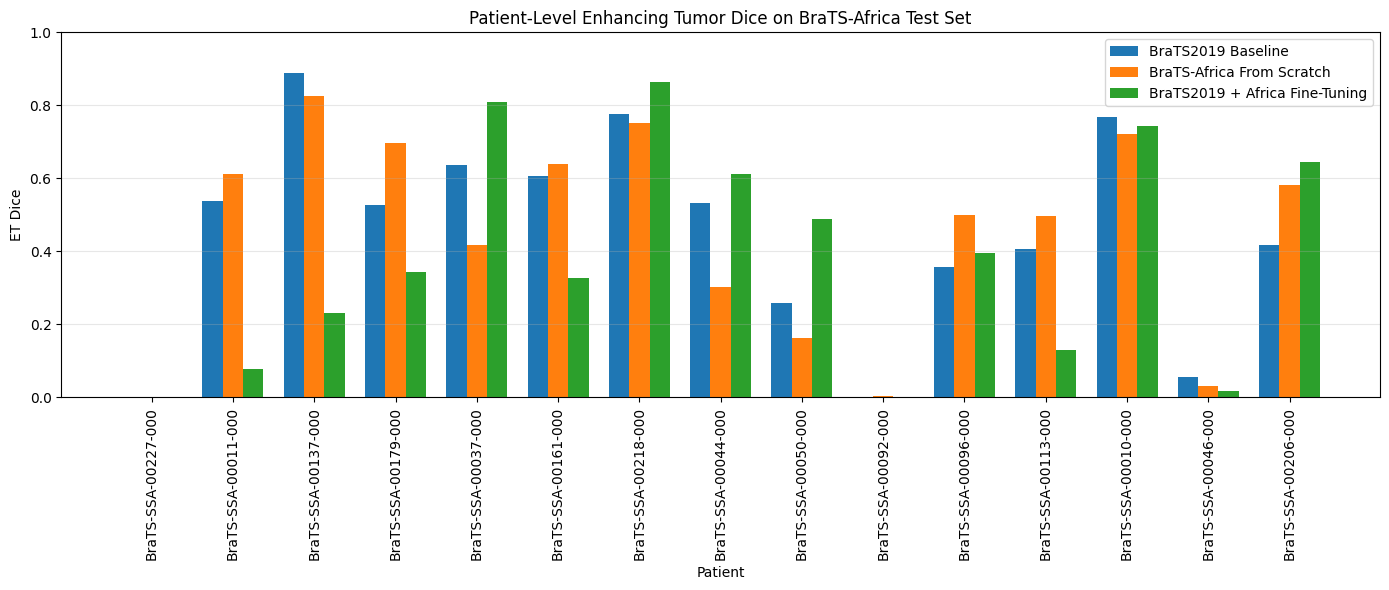

In [ ]:
plt.figure(figsize=(14, 6))

x = np.arange(len(patients))
width = 0.25

plt.bar(
    x - width,
    patient_comparison["ET_Dice_baseline"],
    width,
    label="BraTS2019 Baseline"
)

plt.bar(
    x,
    patient_comparison["ET_Dice_africa"],
    width,
    label="BraTS-Africa From Scratch"
)

plt.bar(
    x + width,
    patient_comparison["ET_Dice_finetune"],
    width,
    label="BraTS2019 + Africa Fine-Tuning"
)

plt.xlabel("Patient")
plt.ylabel("ET Dice")
plt.title("Patient-Level Enhancing Tumor Dice on BraTS-Africa Test Set")

plt.xticks(x, patients, rotation=90)
plt.ylim(0, 1)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import wilcoxon

statistical_results = []

for metric in metrics:

    baseline_values = baseline_results[metric].values
    africa_values = africa_results[metric].values
    finetune_values = finetune_results[metric].values

    # Baseline vs Africa
    stat_ba, p_ba = wilcoxon(
        baseline_values,
        africa_values,
        zero_method="wilcox",
        alternative="two-sided"
    )

    # Baseline vs Fine-tuning
    stat_bf, p_bf = wilcoxon(
        baseline_values,
        finetune_values,
        zero_method="wilcox",
        alternative="two-sided"
    )

    statistical_results.append({
        "Metric": metric,
        "Baseline vs Africa p-value": p_ba,
        "Baseline vs Fine-tuning p-value": p_bf
    })

stats_df = pd.DataFrame(statistical_results)

display(stats_df)

,Metric,Baseline vs Africa p-value,Baseline vs Fine-tuning p-value
0,WT_Dice,0.599487,0.004272
1,TC_Dice,0.977966,0.302795
2,ET_Dice,1.000000,0.488708


In [ ]:
stats_df["Baseline vs Africa significant"] = (
    stats_df["Baseline vs Africa p-value"] < 0.05
)

stats_df["Baseline vs Fine-tuning significant"] = (
    stats_df["Baseline vs Fine-tuning p-value"] < 0.05
)

display(stats_df)

,Metric,Baseline vs Africa p-value,Baseline vs Fine-tuning p-value,Baseline vs Africa significant,Baseline vs Fine-tuning significant
0,WT_Dice,0.599487,0.004272,False,True
1,TC_Dice,0.977966,0.302795,False,False
2,ET_Dice,1.000000,0.488708,False,False


In [ ]:
statistical_africa_ft = []

for metric in metrics:

    africa_values = africa_results[metric].values
    finetune_values = finetune_results[metric].values

    stat, p = wilcoxon(
        africa_values,
        finetune_values,
        zero_method="wilcox",
        alternative="two-sided"
    )

    statistical_africa_ft.append({
        "Metric": metric,
        "Africa From Scratch vs Fine-Tuning p-value": p
    })

stats_africa_ft_df = pd.DataFrame(statistical_africa_ft)

display(stats_africa_ft_df)

,Metric,Africa From Scratch vs Fine-Tuning p-value
0,WT_Dice,0.004272
1,TC_Dice,0.875291
2,ET_Dice,0.470338


In [ ]:
hard_cases = patient_comparison[
    [
        "patient_id",
        "WT_Dice_baseline",
        "TC_Dice_baseline",
        "ET_Dice_baseline",
        "WT_Dice_africa",
        "TC_Dice_africa",
        "ET_Dice_africa",
        "WT_Dice_finetune",
        "TC_Dice_finetune",
        "ET_Dice_finetune"
    ]
].sort_values("WT_Dice_baseline")

display(hard_cases)

,patient_id,WT_Dice_baseline,TC_Dice_baseline,ET_Dice_baseline,WT_Dice_africa,TC_Dice_africa,ET_Dice_africa,WT_Dice_finetune,TC_Dice_finetune,ET_Dice_finetune
0,BraTS-SSA-00227-000,2.454590e-09,8.467400e-09,1.477105e-08,0.010891,0.000000,0.000000,0.000000,0.000000,0.000000
9,BraTS-SSA-00092-000,7.089513e-01,9.516516e-02,9.389671e-09,0.469280,0.002706,0.003830,0.645056,0.062498,0.000000
10,BraTS-SSA-00096-000,7.332434e-01,5.778284e-01,3.583324e-01,0.880903,0.080759,0.500268,0.880482,0.102265,0.396952
5,BraTS-SSA-00161-000,7.564723e-01,7.771878e-01,6.066958e-01,0.696630,0.492966,0.640474,0.358226,0.285435,0.327440
11,BraTS-SSA-00113-000,8.387945e-01,7.889172e-01,4.066340e-01,0.816077,0.494657,0.495944,0.613971,0.678553,0.130792
7,BraTS-SSA-00044-000,8.464425e-01,3.253822e-01,5.334145e-01,0.830989,0.407924,0.303140,0.681570,0.540578,0.612714
6,BraTS-SSA-00218-000,8.528900e-01,7.761713e-01,7.775721e-01,0.894716,0.889541,0.751106,0.890773,0.908075,0.865242
4,BraTS-SSA-00037-000,8.772631e-01,2.263406e-01,6.360029e-01,0.889978,0.439859,0.418097,0.921853,0.548696,0.808427
8,BraTS-SSA-00050-000,9.053113e-01,8.367669e-02,2.575777e-01,0.907160,0.168087,0.163079,0.504649,0.442347,0.489527
3,BraTS-SSA-00179-000,9.149311e-01,8.330401e-01,5.265435e-01,0.911890,0.821836,0.696112,0.543433,0.294669,0.342441


In [ ]:
for metric in metrics:

    baseline_values = baseline_results[metric].values
    africa_values = africa_results[metric].values

    improved = np.sum(africa_values > baseline_values)
    decreased = np.sum(africa_values < baseline_values)
    equal = np.sum(africa_values == baseline_values)

    print(f"\n{metric}")
    print("Africa > Baseline:", improved)
    print("Africa < Baseline:", decreased)
    print("Equal:", equal)


WT_Dice
Africa > Baseline: 7
Africa < Baseline: 8
Equal: 0

TC_Dice
Africa > Baseline: 8
Africa < Baseline: 7
Equal: 0

ET_Dice
Africa > Baseline: 7
Africa < Baseline: 8
Equal: 0


In [ ]:
for metric in metrics:

    baseline_mean = baseline_results[metric].mean()
    africa_mean = africa_results[metric].mean()
    finetune_mean = finetune_results[metric].mean()

    baseline_std = baseline_results[metric].std()
    africa_std = africa_results[metric].std()
    finetune_std = finetune_results[metric].std()

    print("=" * 60)
    print(metric)

    print(
        f"BraTS2019 Baseline: "
        f"{baseline_mean:.4f} ± {baseline_std:.4f}"
    )

    print(
        f"BraTS-Africa From Scratch: "
        f"{africa_mean:.4f} ± {africa_std:.4f}"
    )

    print(
        f"BraTS2019 + Africa Fine-Tuning: "
        f"{finetune_mean:.4f} ± {finetune_std:.4f}"
    )

WT_Dice
BraTS2019 Baseline: 0.8076 ± 0.2365
BraTS-Africa From Scratch: 0.7975 ± 0.2503
BraTS2019 + Africa Fine-Tuning: 0.6104 ± 0.2666
TC_Dice
BraTS2019 Baseline: 0.4776 ± 0.3188
BraTS-Africa From Scratch: 0.4549 ± 0.3273
BraTS2019 + Africa Fine-Tuning: 0.3806 ± 0.3106
ET_Dice
BraTS2019 Baseline: 0.4512 ± 0.2790
BraTS-Africa From Scratch: 0.4496 ± 0.2846
BraTS2019 + Africa Fine-Tuning: 0.3792 ± 0.3032


In [ ]:
analysis_dir = os.path.join(
    base_path,
    "final_analysis"
)

os.makedirs(analysis_dir, exist_ok=True)

# Combined patient-level results
all_results.to_csv(
    os.path.join(analysis_dir, "all_model_results.csv"),
    index=False
)

# Summary
summary_df.to_csv(
    os.path.join(analysis_dir, "summary_mean_std.csv"),
    index=False
)

# Differences
difference_table.to_csv(
    os.path.join(analysis_dir, "model_differences.csv")
)

# Percentage changes
percentage_change.to_csv(
    os.path.join(analysis_dir, "percentage_changes.csv")
)

# Statistics
stats_df.to_csv(
    os.path.join(analysis_dir, "wilcoxon_baseline_comparisons.csv"),
    index=False
)

stats_africa_ft_df.to_csv(
    os.path.join(analysis_dir, "wilcoxon_africa_finetuning.csv"),
    index=False
)

# Patient comparison
patient_comparison.to_csv(
    os.path.join(analysis_dir, "patient_level_comparison.csv"),
    index=False
)

print("All analysis files saved successfully!")
print(analysis_dir)

All analysis files saved successfully!
/content/drive/MyDrive/Master_SIIA/final_analysis


In [ ]:
print("=" * 70)
print("FINAL ANALYSIS CHECK")
print("=" * 70)

print("\nNumber of test patients:", len(baseline_results))

print("\nMean Dice:")
for model in models:
    row = mean_table.loc[model]

    print(f"\n{model}")
    print(f"  WT: {row['WT_Dice']:.4f}")
    print(f"  TC: {row['TC_Dice']:.4f}")
    print(f"  ET: {row['ET_Dice']:.4f}")

print("\nAnalysis directory:")
print(analysis_dir)

print("\nDone ✅")

FINAL ANALYSIS CHECK

Number of test patients: 15

Mean Dice:

BraTS2019 Baseline
  WT: 0.8076
  TC: 0.4776
  ET: 0.4512

BraTS-Africa From Scratch
  WT: 0.7975
  TC: 0.4549
  ET: 0.4496

BraTS2019 + Africa Fine-Tuning
  WT: 0.6104
  TC: 0.3806
  ET: 0.3792

Analysis directory:
/content/drive/MyDrive/Master_SIIA/final_analysis

Done ✅


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/Master_SIIA/BraTS-Africa"

print("Searching for metadata files...\n")

metadata_extensions = (
    ".csv", ".xlsx", ".xls", ".json",
    ".tsv", ".txt"
)

found_files = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith(metadata_extensions):
            full_path = os.path.join(root, file)
            found_files.append(full_path)

if found_files:
    print(f"Found {len(found_files)} possible metadata file(s):\n")

    for file in found_files:
        print(file)
else:
    print("No CSV / Excel / JSON / TSV / TXT metadata files found.")

Searching for metadata files...

No CSV / Excel / JSON / TSV / TXT metadata files found.


In [ ]:
# Check what is currently available after Colab reconnect

required_variables = [
    "UNet3D",
    "normalize_mri",
    "test_patients",
    "baseline_results",
    "africa_results",
    "finetune_results"
]

print("=" * 60)
print("ENVIRONMENT CHECK")
print("=" * 60)

for name in required_variables:
    if name in globals():
        print(f"✅ {name}")
    else:
        print(f"❌ {name}")

print("\nGPU check:")

import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

ENVIRONMENT CHECK
❌ UNet3D
❌ normalize_mri
❌ test_patients
❌ baseline_results
❌ africa_results
❌ finetune_results

GPU check:
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [ ]:
# ============================================================
# RESTORE ENVIRONMENT AFTER COLAB DISCONNECT
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import nibabel as nib

import torch
import torch.nn as nn
import torch.nn.functional as F

# ------------------------------------------------------------
# 1. Device
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 2. Paths
# ------------------------------------------------------------

base_path = "/content/drive/MyDrive/Master_SIIA"

dataset_path = os.path.join(
    base_path,
    "BraTS-Africa"
)

glioma_path = os.path.join(
    dataset_path,
    "95_Glioma"
)

baseline_checkpoint = os.path.join(
    base_path,
    "checkpoints_BraTS2019",
    "best_model.pth"
)

africa_checkpoint = os.path.join(
    base_path,
    "checkpoints",
    "best_model.pth"
)

finetune_checkpoint = os.path.join(
    base_path,
    "checkpoints_finetune_BraTS_Africa",
    "best_model.pth"
)


# ------------------------------------------------------------
# 3. Check paths
# ------------------------------------------------------------

print("\nPATH CHECK")

print(
    "Africa dataset:",
    os.path.exists(glioma_path)
)

print(
    "Baseline checkpoint:",
    os.path.exists(baseline_checkpoint)
)

print(
    "Africa checkpoint:",
    os.path.exists(africa_checkpoint)
)

print(
    "Fine-tuned checkpoint:",
    os.path.exists(finetune_checkpoint)
)


# ------------------------------------------------------------
# 4. MRI normalization
# ------------------------------------------------------------

def normalize_mri(image):

    mask = image > 0

    normalized = np.zeros_like(
        image,
        dtype=np.float32
    )

    if np.any(mask):

        mean = np.mean(image[mask])
        std = np.std(image[mask])

        if std > 0:
            normalized[mask] = (
                image[mask] - mean
            ) / std

    return normalized


# ------------------------------------------------------------
# 5. 3D U-Net architecture
# ------------------------------------------------------------

class DoubleConv(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        self.conv = nn.Sequential(

            nn.Conv3d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm3d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Conv3d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm3d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            )
        )

    def forward(self, x):

        return self.conv(x)


class UNet3D(nn.Module):

    def __init__(
        self,
        in_channels=4,
        out_channels=4
    ):

        super().__init__()

        self.enc1 = DoubleConv(
            in_channels,
            16
        )

        self.pool1 = nn.MaxPool3d(2)

        self.enc2 = DoubleConv(
            16,
            32
        )

        self.pool2 = nn.MaxPool3d(2)

        self.enc3 = DoubleConv(
            32,
            64
        )

        self.pool3 = nn.MaxPool3d(2)

        self.bottleneck = DoubleConv(
            64,
            128
        )

        self.up3 = nn.ConvTranspose3d(
            128,
            64,
            2,
            2
        )

        self.dec3 = DoubleConv(
            128,
            64
        )

        self.up2 = nn.ConvTranspose3d(
            64,
            32,
            2,
            2
        )

        self.dec2 = DoubleConv(
            64,
            32
        )

        self.up1 = nn.ConvTranspose3d(
            32,
            16,
            2,
            2
        )

        self.dec1 = DoubleConv(
            32,
            16
        )

        self.final_conv = nn.Conv3d(
            16,
            out_channels,
            kernel_size=1
        )


    def forward(self, x):

        e1 = self.enc1(x)
        p1 = self.pool1(e1)

        e2 = self.enc2(p1)
        p2 = self.pool2(e2)

        e3 = self.enc3(p2)
        p3 = self.pool3(e3)

        b = self.bottleneck(p3)

        d3 = self.up3(b)
        d3 = torch.cat(
            [d3, e3],
            dim=1
        )
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat(
            [d2, e2],
            dim=1
        )
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat(
            [d1, e1],
            dim=1
        )
        d1 = self.dec1(d1)

        return self.final_conv(d1)


# ------------------------------------------------------------
# 6. Recreate EXACT Africa split
# ------------------------------------------------------------

patients = sorted([
    p
    for p in os.listdir(glioma_path)
    if os.path.isdir(
        os.path.join(
            glioma_path,
            p
        )
    )
])

random.seed(42)
random.shuffle(patients)

n = len(patients)

n_train = int(
    0.70 * n
)

n_val = int(
    0.15 * n
)

train_patients = patients[
    :n_train
]

val_patients = patients[
    n_train:
    n_train + n_val
]

test_patients = patients[
    n_train + n_val:
]


print("\nDATA SPLIT")

print(
    "Total:",
    len(patients)
)

print(
    "Train:",
    len(train_patients)
)

print(
    "Validation:",
    len(val_patients)
)

print(
    "Test:",
    len(test_patients)
)


# ------------------------------------------------------------
# 7. Load previous Dice CSV files
# ------------------------------------------------------------

baseline_df = pd.read_csv(
    os.path.join(
        base_path,
        "brats2019_baseline_on_africa_test.csv"
    )
)

africa_df = pd.read_csv(
    os.path.join(
        base_path,
        "full_volume_test_results.csv"
    )
)

finetune_df = pd.read_csv(
    os.path.join(
        base_path,
        "finetuned_model_on_africa_test.csv"
    )
)


# ------------------------------------------------------------
# 8. Final environment check
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ENVIRONMENT RESTORED")
print("=" * 60)

print(
    "UNet3D: ✅"
)

print(
    "normalize_mri: ✅"
)

print(
    "Test patients:",
    len(test_patients)
)

print(
    "Baseline results:",
    baseline_df.shape
)

print(
    "Africa results:",
    africa_df.shape
)

print(
    "Fine-tuning results:",
    finetune_df.shape
)

print("\nReady for calibration and uncertainty analysis ✅")

Device: cuda
GPU: Tesla T4

PATH CHECK
Africa dataset: True
Baseline checkpoint: True
Africa checkpoint: True
Fine-tuned checkpoint: True

DATA SPLIT
Total: 95
Train: 66
Validation: 14
Test: 15

ENVIRONMENT RESTORED
UNet3D: ✅
normalize_mri: ✅
Test patients: 15
Baseline results: (15, 4)
Africa results: (15, 4)
Fine-tuning results: (15, 4)

Ready for calibration and uncertainty analysis ✅


In [ ]:
# ============================================================
# FIX CHECKPOINT LOADING FOR NEW PYTORCH
# ============================================================

def load_saved_model(checkpoint_path, model_name):

    model = UNet3D(
        in_channels=4,
        out_channels=4
    ).to(device)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.eval()

    print(f"✅ {model_name} loaded")

    if "epoch" in checkpoint:
        print("   Best epoch:", checkpoint["epoch"])

    if "val_dice" in checkpoint:
        print(
            "   Validation Dice:",
            checkpoint["val_dice"]
        )

    return model


baseline_model = load_saved_model(
    baseline_checkpoint,
    "BraTS2019 Baseline"
)

africa_model = load_saved_model(
    africa_checkpoint,
    "BraTS-Africa From Scratch"
)

finetune_model = load_saved_model(
    finetune_checkpoint,
    "BraTS2019 + Africa Fine-Tuning"
)

print("\nAll three models loaded successfully ✅")

✅ BraTS2019 Baseline loaded
   Best epoch: 10
   Validation Dice: 0.49672472819611535
✅ BraTS-Africa From Scratch loaded
   Best epoch: 10
   Validation Dice: 0.5120793239705373
✅ BraTS2019 + Africa Fine-Tuning loaded
   Best epoch: 6
   Validation Dice: 0.6085158248919823

All three models loaded successfully ✅


In [ ]:
# ============================================================
# FULL-VOLUME PROBABILITY INFERENCE
# ============================================================

def full_volume_probabilities(
    model,
    patient_id,
    data_path,
    patch_size=(96, 96, 96),
    stride=(64, 64, 64)
):

    patient_path = os.path.join(
        data_path,
        patient_id
    )

    modalities = [
        "t1n",
        "t1c",
        "t2w",
        "t2f"
    ]

    # -------------------------------
    # Load MRI modalities
    # -------------------------------

    images = []

    for modality in modalities:

        file_path = os.path.join(
            patient_path,
            f"{patient_id}-{modality}.nii.gz"
        )

        img = nib.load(
            file_path
        ).get_fdata()

        img = normalize_mri(img)

        images.append(
            img.astype(np.float32)
        )

    image = np.stack(
        images,
        axis=0
    )

    # -------------------------------
    # Load ground truth
    # -------------------------------

    seg_path = os.path.join(
        patient_path,
        f"{patient_id}-seg.nii.gz"
    )

    target = nib.load(
        seg_path
    ).get_fdata().astype(np.int64)

    C, D, H, W = image.shape

    probability_sum = np.zeros(
        (4, D, H, W),
        dtype=np.float32
    )

    count_map = np.zeros(
        (D, H, W),
        dtype=np.float32
    )

    # -------------------------------
    # Patch positions
    # -------------------------------

    def get_positions(
        size,
        patch,
        step
    ):

        positions = list(
            range(
                0,
                max(size - patch + 1, 1),
                step
            )
        )

        last_position = size - patch

        if positions[-1] != last_position:
            positions.append(
                last_position
            )

        return positions


    z_positions = get_positions(
        D,
        patch_size[0],
        stride[0]
    )

    y_positions = get_positions(
        H,
        patch_size[1],
        stride[1]
    )

    x_positions = get_positions(
        W,
        patch_size[2],
        stride[2]
    )

    # -------------------------------
    # Inference
    # -------------------------------

    model.eval()

    with torch.no_grad():

        for z in z_positions:
            for y in y_positions:
                for x in x_positions:

                    patch = image[
                        :,
                        z:z + patch_size[0],
                        y:y + patch_size[1],
                        x:x + patch_size[2]
                    ]

                    patch_tensor = (
                        torch.from_numpy(patch)
                        .unsqueeze(0)
                        .float()
                        .to(device)
                    )

                    logits = model(
                        patch_tensor
                    )

                    probabilities = F.softmax(
                        logits,
                        dim=1
                    )

                    probabilities = (
                        probabilities
                        .squeeze(0)
                        .cpu()
                        .numpy()
                    )

                    probability_sum[
                        :,
                        z:z + patch_size[0],
                        y:y + patch_size[1],
                        x:x + patch_size[2]
                    ] += probabilities

                    count_map[
                        z:z + patch_size[0],
                        y:y + patch_size[1],
                        x:x + patch_size[2]
                    ] += 1

    # Avoid division by zero
    count_map[
        count_map == 0
    ] = 1

    probabilities = (
        probability_sum /
        count_map[None, ...]
    )

    return probabilities, target


print("Full-volume probability inference function ready ✅")

Full-volume probability inference function ready ✅


In [ ]:
# ============================================================
# TEST ON ONE PATIENT
# ============================================================

test_patient = test_patients[0]

print(
    "Testing patient:",
    test_patient
)

probs_test, target_test = full_volume_probabilities(
    baseline_model,
    test_patient,
    glioma_path
)

print("\nProbability shape:")
print(probs_test.shape)

print("\nTarget shape:")
print(target_test.shape)

print("\nProbability range:")
print(
    "Min:",
    probs_test.min()
)

print(
    "Max:",
    probs_test.max()
)

probability_sum_check = probs_test.sum(
    axis=0
)

print("\nMean sum of class probabilities:")
print(
    probability_sum_check.mean()
)

print("\nExpected value ≈ 1.0")

prediction_test = np.argmax(
    probs_test,
    axis=0
)

print("\nPredicted labels:")
print(
    np.unique(prediction_test)
)

print("\nGround-truth labels:")
print(
    np.unique(target_test)
)

Testing patient: BraTS-SSA-00227-000

Probability shape:
(4, 240, 240, 155)

Target shape:
(240, 240, 155)

Probability range:
Min: 0.043323796
Max: 0.575189

Mean sum of class probabilities:
1.0

Expected value ≈ 1.0

Predicted labels:
[0 1 3]

Ground-truth labels:
[0 1 2 3]


In [ ]:
# ============================================================
# CALIBRATION METRICS
# ECE + Brier Score + Confidence + Accuracy
# ============================================================

def compute_calibration_metrics(
    probabilities,
    target,
    brain_mask,
    n_bins=15
):
    # Keep brain voxels only
    probs = probabilities[:, brain_mask].T
    labels = target[brain_mask]

    # Predicted class and confidence
    predictions = np.argmax(probs, axis=1)
    confidence = np.max(probs, axis=1)

    correct = (predictions == labels).astype(np.float32)

    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------
    accuracy = correct.mean()

    # --------------------------------------------------------
    # Mean confidence
    # --------------------------------------------------------
    mean_confidence = confidence.mean()

    # --------------------------------------------------------
    # Expected Calibration Error (ECE)
    # --------------------------------------------------------
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)

    ece = 0.0

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == 0:
            bin_mask = (
                (confidence >= lower) &
                (confidence <= upper)
            )
        else:
            bin_mask = (
                (confidence > lower) &
                (confidence <= upper)
            )

        if np.any(bin_mask):

            bin_accuracy = correct[bin_mask].mean()
            bin_confidence = confidence[bin_mask].mean()

            bin_weight = bin_mask.mean()

            ece += (
                np.abs(
                    bin_accuracy -
                    bin_confidence
                )
                * bin_weight
            )

    # --------------------------------------------------------
    # Multiclass Brier Score
    # --------------------------------------------------------
    one_hot = np.eye(4, dtype=np.float32)[labels]

    brier = np.mean(
        np.sum(
            (probs - one_hot) ** 2,
            axis=1
        )
    )

    return {
        "Accuracy": float(accuracy),
        "Mean_Confidence": float(mean_confidence),
        "ECE": float(ece),
        "Brier_Score": float(brier)
    }


print("Calibration metric function ready ✅")

Calibration metric function ready ✅


In [ ]:
# ============================================================
# CALIBRATION TEST ON ONE PATIENT
# ============================================================

# Brain mask:
# voxel considered brain if at least one MRI modality is non-zero

patient_path = os.path.join(
    glioma_path,
    test_patient
)

t1n = nib.load(
    os.path.join(
        patient_path,
        f"{test_patient}-t1n.nii.gz"
    )
).get_fdata()

brain_mask_test = t1n > 0

calibration_test = compute_calibration_metrics(
    probs_test,
    target_test,
    brain_mask_test,
    n_bins=15
)

print("=" * 60)
print("CALIBRATION TEST")
print("=" * 60)

print("Patient:", test_patient)
print("Brain voxels:", brain_mask_test.sum())

for metric, value in calibration_test.items():
    print(
        f"{metric}: {value:.6f}"
    )

CALIBRATION TEST
Patient: BraTS-SSA-00227-000
Brain voxels: 1283319
Accuracy: 0.996827
Mean_Confidence: 0.504752
ECE: 0.492080
Brier_Score: 0.356548


In [ ]:
# ============================================================
# CALIBRATION ANALYSIS — ALL 3 MODELS × 15 TEST PATIENTS
# ============================================================

calibration_results = []

models_dict = {
    "BraTS2019 Baseline": baseline_model,
    "BraTS-Africa From Scratch": africa_model,
    "BraTS2019 + Africa Fine-Tuning": finetune_model
}

for model_name, current_model in models_dict.items():

    print("\n" + "=" * 70)
    print("MODEL:", model_name)
    print("=" * 70)

    for i, patient_id in enumerate(test_patients):

        print(
            f"[{i+1}/{len(test_patients)}] {patient_id}",
            end=" ... "
        )

        # --------------------------------------------
        # Full-volume probabilities
        # --------------------------------------------

        probabilities, target = full_volume_probabilities(
            current_model,
            patient_id,
            glioma_path
        )

        # --------------------------------------------
        # Brain mask
        # --------------------------------------------

        patient_path = os.path.join(
            glioma_path,
            patient_id
        )

        t1n = nib.load(
            os.path.join(
                patient_path,
                f"{patient_id}-t1n.nii.gz"
            )
        ).get_fdata()

        brain_mask = t1n > 0

        # --------------------------------------------
        # Calibration metrics
        # --------------------------------------------

        metrics_patient = compute_calibration_metrics(
            probabilities,
            target,
            brain_mask,
            n_bins=15
        )

        calibration_results.append({
            "Model": model_name,
            "Patient": patient_id,
            "Accuracy": metrics_patient["Accuracy"],
            "Mean_Confidence": metrics_patient["Mean_Confidence"],
            "ECE": metrics_patient["ECE"],
            "Brier_Score": metrics_patient["Brier_Score"]
        })

        print(
            f"ECE={metrics_patient['ECE']:.4f}, "
            f"Brier={metrics_patient['Brier_Score']:.4f}"
        )

        # Free memory
        del probabilities
        del target
        del t1n
        del brain_mask

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ============================================================
# Convert to DataFrame
# ============================================================

calibration_df = pd.DataFrame(
    calibration_results
)

print("\n" + "=" * 70)
print("CALIBRATION ANALYSIS COMPLETE")
print("=" * 70)

display(calibration_df.head())


# ============================================================
# Save
# ============================================================

analysis_dir = os.path.join(
    base_path,
    "final_analysis"
)

os.makedirs(
    analysis_dir,
    exist_ok=True
)

calibration_file = os.path.join(
    analysis_dir,
    "calibration_three_models.csv"
)

calibration_df.to_csv(
    calibration_file,
    index=False
)

print("\nSaved ✅")
print(calibration_file)


MODEL: BraTS2019 Baseline
[1/15] BraTS-SSA-00227-000 ... ECE=0.4921, Brier=0.3565
[2/15] BraTS-SSA-00011-000 ... ECE=0.4348, Brier=0.3872
[3/15] BraTS-SSA-00137-000 ... ECE=0.4650, Brier=0.3611
[4/15] BraTS-SSA-00179-000 ... ECE=0.4382, Brier=0.3813
[5/15] BraTS-SSA-00037-000 ... ECE=0.4970, Brier=0.3786
[6/15] BraTS-SSA-00161-000 ... ECE=0.4294, Brier=0.3926
[7/15] BraTS-SSA-00218-000 ... ECE=0.4780, Brier=0.3820
[8/15] BraTS-SSA-00044-000 ... ECE=0.4376, Brier=0.4593
[9/15] BraTS-SSA-00050-000 ... ECE=0.4733, Brier=0.4123
[10/15] BraTS-SSA-00092-000 ... ECE=0.4851, Brier=0.3891
[11/15] BraTS-SSA-00096-000 ... ECE=0.3888, Brier=0.4061
[12/15] BraTS-SSA-00113-000 ... ECE=0.4153, Brier=0.4001
[13/15] BraTS-SSA-00010-000 ... ECE=0.4575, Brier=0.3680
[14/15] BraTS-SSA-00046-000 ... ECE=0.4734, Brier=0.3905
[15/15] BraTS-SSA-00206-000 ... ECE=0.3897, Brier=0.4455

MODEL: BraTS-Africa From Scratch
[1/15] BraTS-SSA-00227-000 ... ECE=0.3564, Brier=0.1793
[2/15] BraTS-SSA-00011-000 ... ECE=0.

,Model,Patient,Accuracy,Mean_Confidence,ECE,Brier_Score
0,BraTS2019 Baseline,BraTS-SSA-00227-000,0.996827,0.504752,0.492080,0.356548
1,BraTS2019 Baseline,BraTS-SSA-00011-000,0.937864,0.523693,0.434797,0.387168
2,BraTS2019 Baseline,BraTS-SSA-00137-000,0.978035,0.514549,0.464967,0.361112
3,BraTS2019 Baseline,BraTS-SSA-00179-000,0.950223,0.512059,0.438201,0.381268
4,BraTS2019 Baseline,BraTS-SSA-00037-000,0.986426,0.493964,0.497026,0.378597



Saved ✅
/content/drive/MyDrive/Master_SIIA/final_analysis/calibration_three_models.csv


In [ ]:
# ============================================================
# CALIBRATION SUMMARY
# ============================================================

calibration_summary = calibration_df.groupby(
    "Model"
)[
    [
        "Accuracy",
        "Mean_Confidence",
        "ECE",
        "Brier_Score"
    ]
].agg(
    ["mean", "std"]
)

print("=" * 70)
print("CALIBRATION SUMMARY")
print("=" * 70)

display(calibration_summary)

CALIBRATION SUMMARY


Accuracy           Mean_Confidence            \
                                    mean       std            mean       std   
Model                                                                          
BraTS-Africa From Scratch       0.947961  0.039195        0.635354  0.011239   
BraTS2019 + Africa Fine-Tuning  0.957956  0.032733        0.538347  0.009246   
BraTS2019 Baseline              0.942486  0.040697        0.504038  0.009187   

                                     ECE           Brier_Score            
                                    mean       std        mean       std  
Model                                                                     
BraTS-Africa From Scratch       0.326829  0.024479    0.229658  0.041359  
BraTS2019 + Africa Fine-Tuning  0.426696  0.024922    0.338077  0.026070  
BraTS2019 Baseline              0.450349  0.034730    0.394012  0.028304

In [ ]:
for model_name in models_dict.keys():

    model_data = calibration_df[
        calibration_df["Model"] == model_name
    ]

    print("\n" + "=" * 60)
    print(model_name)

    print(
        f"Accuracy: "
        f"{model_data['Accuracy'].mean():.4f} ± "
        f"{model_data['Accuracy'].std():.4f}"
    )

    print(
        f"Mean Confidence: "
        f"{model_data['Mean_Confidence'].mean():.4f} ± "
        f"{model_data['Mean_Confidence'].std():.4f}"
    )

    print(
        f"ECE: "
        f"{model_data['ECE'].mean():.4f} ± "
        f"{model_data['ECE'].std():.4f}"
    )

    print(
        f"Brier Score: "
        f"{model_data['Brier_Score'].mean():.4f} ± "
        f"{model_data['Brier_Score'].std():.4f}"
    )


BraTS2019 Baseline
Accuracy: 0.9425 ± 0.0407
Mean Confidence: 0.5040 ± 0.0092
ECE: 0.4503 ± 0.0347
Brier Score: 0.3940 ± 0.0283

BraTS-Africa From Scratch
Accuracy: 0.9480 ± 0.0392
Mean Confidence: 0.6354 ± 0.0112
ECE: 0.3268 ± 0.0245
Brier Score: 0.2297 ± 0.0414

BraTS2019 + Africa Fine-Tuning
Accuracy: 0.9580 ± 0.0327
Mean Confidence: 0.5383 ± 0.0092
ECE: 0.4267 ± 0.0249
Brier Score: 0.3381 ± 0.0261


In [ ]:
# ============================================================
# UNCERTAINTY METRICS
# Predictive Entropy
# ============================================================

def compute_uncertainty_metrics(
    probabilities,
    target,
    brain_mask
):
    eps = 1e-8

    # Keep brain voxels only
    probs = probabilities[:, brain_mask].T
    labels = target[brain_mask]

    # Prediction
    predictions = np.argmax(probs, axis=1)

    # Predictive entropy
    entropy = -np.sum(
        probs * np.log(probs + eps),
        axis=1
    )

    # Normalize entropy to [0, 1]
    # Maximum entropy for 4 classes = log(4)
    normalized_entropy = entropy / np.log(4)

    # Correct / incorrect predictions
    correct_mask = predictions == labels
    incorrect_mask = predictions != labels

    mean_entropy = normalized_entropy.mean()

    if np.any(correct_mask):
        correct_entropy = normalized_entropy[
            correct_mask
        ].mean()
    else:
        correct_entropy = np.nan

    if np.any(incorrect_mask):
        incorrect_entropy = normalized_entropy[
            incorrect_mask
        ].mean()
    else:
        incorrect_entropy = np.nan

    # Tumor region only
    tumor_mask = labels > 0

    if np.any(tumor_mask):
        tumor_entropy = normalized_entropy[
            tumor_mask
        ].mean()
    else:
        tumor_entropy = np.nan

    # Background / non-tumor brain
    background_mask = labels == 0

    if np.any(background_mask):
        background_entropy = normalized_entropy[
            background_mask
        ].mean()
    else:
        background_entropy = np.nan

    return {
        "Mean_Entropy": float(mean_entropy),
        "Correct_Entropy": float(correct_entropy),
        "Incorrect_Entropy": float(incorrect_entropy),
        "Tumor_Entropy": float(tumor_entropy),
        "Background_Entropy": float(background_entropy)
    }


print("Uncertainty function ready ✅")

Uncertainty function ready ✅


In [ ]:
uncertainty_test = compute_uncertainty_metrics(
    probs_test,
    target_test,
    brain_mask_test
)

print("=" * 60)
print("UNCERTAINTY TEST")
print("=" * 60)

print("Patient:", test_patient)

for metric, value in uncertainty_test.items():
    print(f"{metric}: {value:.6f}")

UNCERTAINTY TEST
Patient: BraTS-SSA-00227-000
Mean_Entropy: 0.836348
Correct_Entropy: 0.836320
Incorrect_Entropy: 0.845409
Tumor_Entropy: 0.841351
Background_Entropy: 0.836333


In [ ]:
# ============================================================
# UNCERTAINTY — ALL 3 MODELS × 15 TEST PATIENTS
# ============================================================

uncertainty_results = []

for model_name, current_model in models_dict.items():

    print("\n" + "=" * 70)
    print("MODEL:", model_name)
    print("=" * 70)

    for i, patient_id in enumerate(test_patients):

        print(
            f"[{i+1}/{len(test_patients)}] "
            f"{patient_id}",
            end=" ... "
        )

        # Full-volume probabilities
        probabilities, target = full_volume_probabilities(
            current_model,
            patient_id,
            glioma_path
        )

        # Brain mask
        patient_path = os.path.join(
            glioma_path,
            patient_id
        )

        t1n = nib.load(
            os.path.join(
                patient_path,
                f"{patient_id}-t1n.nii.gz"
            )
        ).get_fdata()

        brain_mask = t1n > 0

        # Uncertainty
        metrics_patient = compute_uncertainty_metrics(
            probabilities,
            target,
            brain_mask
        )

        uncertainty_results.append({
            "Model": model_name,
            "Patient": patient_id,
            **metrics_patient
        })

        print(
            f"Entropy="
            f"{metrics_patient['Mean_Entropy']:.4f}, "
            f"Tumor="
            f"{metrics_patient['Tumor_Entropy']:.4f}"
        )

        # Free memory
        del probabilities
        del target
        del t1n
        del brain_mask

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# DataFrame
uncertainty_df = pd.DataFrame(
    uncertainty_results
)

print("\n" + "=" * 70)
print("UNCERTAINTY ANALYSIS COMPLETE")
print("=" * 70)

display(uncertainty_df.head())


# Save
uncertainty_file = os.path.join(
    analysis_dir,
    "uncertainty_three_models.csv"
)

uncertainty_df.to_csv(
    uncertainty_file,
    index=False
)

print("\nSaved ✅")
print(uncertainty_file)


MODEL: BraTS2019 Baseline
[1/15] BraTS-SSA-00227-000 ... Entropy=0.8363, Tumor=0.8414
[2/15] BraTS-SSA-00011-000 ... Entropy=0.8045, Tumor=0.5914
[3/15] BraTS-SSA-00137-000 ... Entropy=0.8208, Tumor=0.5760
[4/15] BraTS-SSA-00179-000 ... Entropy=0.8201, Tumor=0.6557
[5/15] BraTS-SSA-00037-000 ... Entropy=0.8444, Tumor=0.7328
[6/15] BraTS-SSA-00161-000 ... Entropy=0.8351, Tumor=0.8198
[7/15] BraTS-SSA-00218-000 ... Entropy=0.8453, Tumor=0.7864
[8/15] BraTS-SSA-00044-000 ... Entropy=0.8262, Tumor=0.6759
[9/15] BraTS-SSA-00050-000 ... Entropy=0.8458, Tumor=0.7764
[10/15] BraTS-SSA-00092-000 ... Entropy=0.8367, Tumor=0.6645
[11/15] BraTS-SSA-00096-000 ... Entropy=0.8183, Tumor=0.6507
[12/15] BraTS-SSA-00113-000 ... Entropy=0.8341, Tumor=0.7837
[13/15] BraTS-SSA-00010-000 ... Entropy=0.8265, Tumor=0.7104
[14/15] BraTS-SSA-00046-000 ... Entropy=0.8438, Tumor=0.8148
[15/15] BraTS-SSA-00206-000 ... Entropy=0.8360, Tumor=0.8103

MODEL: BraTS-Africa From Scratch
[1/15] BraTS-SSA-00227-000 ... En

,Model,Patient,Mean_Entropy,Correct_Entropy,Incorrect_Entropy,Tumor_Entropy,Background_Entropy
0,BraTS2019 Baseline,BraTS-SSA-00227-000,0.836348,0.836320,0.845409,0.841351,0.836333
1,BraTS2019 Baseline,BraTS-SSA-00011-000,0.804522,0.812102,0.690111,0.591401,0.838502
2,BraTS2019 Baseline,BraTS-SSA-00137-000,0.820760,0.823153,0.714205,0.576000,0.838914
3,BraTS2019 Baseline,BraTS-SSA-00179-000,0.820052,0.819483,0.830912,0.655706,0.842996
4,BraTS2019 Baseline,BraTS-SSA-00037-000,0.844355,0.845154,0.786319,0.732791,0.846723



Saved ✅
/content/drive/MyDrive/Master_SIIA/final_analysis/uncertainty_three_models.csv


In [ ]:
print("=" * 70)
print("UNCERTAINTY SUMMARY")
print("=" * 70)

for model_name in models_dict.keys():

    data = uncertainty_df[
        uncertainty_df["Model"] == model_name
    ]

    print("\n" + "=" * 60)
    print(model_name)

    for metric in [
        "Mean_Entropy",
        "Correct_Entropy",
        "Incorrect_Entropy",
        "Tumor_Entropy",
        "Background_Entropy"
    ]:

        print(
            f"{metric}: "
            f"{data[metric].mean():.4f} ± "
            f"{data[metric].std():.4f}"
        )

UNCERTAINTY SUMMARY

BraTS2019 Baseline
Mean_Entropy: 0.8316 ± 0.0120
Correct_Entropy: 0.8328 ± 0.0111
Incorrect_Entropy: 0.8108 ± 0.0689
Tumor_Entropy: 0.7260 ± 0.0864
Background_Entropy: 0.8428 ± 0.0044

BraTS-Africa From Scratch
Mean_Entropy: 0.7388 ± 0.0125
Correct_Entropy: 0.7374 ± 0.0096
Incorrect_Entropy: 0.7878 ± 0.0886
Tumor_Entropy: 0.6668 ± 0.0931
Background_Entropy: 0.7469 ± 0.0065

BraTS2019 + Africa Fine-Tuning
Mean_Entropy: 0.7989 ± 0.0120
Correct_Entropy: 0.7979 ± 0.0127
Incorrect_Entropy: 0.8441 ± 0.0556
Tumor_Entropy: 0.7173 ± 0.0894
Background_Entropy: 0.8077 ± 0.0041


In [ ]:
# ============================================================
# FINAL STATISTICAL TESTS
# Calibration + Uncertainty
# ============================================================

from scipy.stats import wilcoxon
import pandas as pd
import numpy as np
import os

comparisons = [
    ("BraTS2019 Baseline", "BraTS-Africa From Scratch"),
    ("BraTS2019 Baseline", "BraTS2019 + Africa Fine-Tuning"),
    ("BraTS-Africa From Scratch", "BraTS2019 + Africa Fine-Tuning")
]

metrics_to_test = [
    ("Calibration", calibration_df, "ECE"),
    ("Calibration", calibration_df, "Brier_Score"),
    ("Uncertainty", uncertainty_df, "Mean_Entropy"),
    ("Uncertainty", uncertainty_df, "Tumor_Entropy")
]

stat_results = []

for category, df, metric in metrics_to_test:

    for model1, model2 in comparisons:

        # Align by patient ID
        d1 = (
            df[df["Model"] == model1]
            .set_index("Patient")[metric]
        )

        d2 = (
            df[df["Model"] == model2]
            .set_index("Patient")[metric]
        )

        common_patients = d1.index.intersection(d2.index)

        values1 = d1.loc[common_patients].values
        values2 = d2.loc[common_patients].values

        stat, p = wilcoxon(
            values1,
            values2,
            alternative="two-sided"
        )

        stat_results.append({
            "Category": category,
            "Metric": metric,
            "Model_1": model1,
            "Model_2": model2,
            "N": len(common_patients),
            "Wilcoxon_Statistic": stat,
            "P_Value": p,
            "Significant_p<0.05": p < 0.05
        })


final_stats_df = pd.DataFrame(stat_results)

display(final_stats_df)

# Save
stats_file = os.path.join(
    analysis_dir,
    "final_calibration_uncertainty_statistics.csv"
)

final_stats_df.to_csv(
    stats_file,
    index=False
)

print("\nSaved ✅")
print(stats_file)

,Category,Metric,Model_1,Model_2,N,Wilcoxon_Statistic,P_Value,Significant_p<0.05
0,Calibration,ECE,BraTS2019 Baseline,BraTS-Africa From Scratch,15,0.0,0.000061,True
1,Calibration,ECE,BraTS2019 Baseline,BraTS2019 + Africa Fine-Tuning,15,13.0,0.005371,True
2,Calibration,ECE,BraTS-Africa From Scratch,BraTS2019 + Africa Fine-Tuning,15,0.0,0.000061,True
3,Calibration,Brier_Score,BraTS2019 Baseline,BraTS-Africa From Scratch,15,0.0,0.000061,True
4,Calibration,Brier_Score,BraTS2019 Baseline,BraTS2019 + Africa Fine-Tuning,15,0.0,0.000061,True
5,Calibration,Brier_Score,BraTS-Africa From Scratch,BraTS2019 + Africa Fine-Tuning,15,0.0,0.000061,True
6,Uncertainty,Mean_Entropy,BraTS2019 Baseline,BraTS-Africa From Scratch,15,0.0,0.000061,True
7,Uncertainty,Mean_Entropy,BraTS2019 Baseline,BraTS2019 + Africa Fine-Tuning,15,0.0,0.000061,True
8,Uncertainty,Mean_Entropy,BraTS-Africa From Scratch,BraTS2019 + Africa Fine-Tuning,15,0.0,0.000061,True
9,Uncertainty,Tumor_Entropy,BraTS2019 Baseline,BraTS-Africa From Scratch,15,17.0,0.012451,True



Saved ✅
/content/drive/MyDrive/Master_SIIA/final_analysis/final_calibration_uncertainty_statistics.csv


In [ ]:
print("=" * 75)
print("FINAL CALIBRATION & UNCERTAINTY STATISTICS")
print("=" * 75)

for _, row in final_stats_df.iterrows():

    print(
        f"\n{row['Metric']}: "
        f"{row['Model_1']} vs {row['Model_2']}"
    )

    print(
        f"p = {row['P_Value']:.6f}"
    )

    if row["Significant_p<0.05"]:
        print("Statistically significant (p < 0.05)")
    else:
        print("Not statistically significant (p >= 0.05)")

FINAL CALIBRATION & UNCERTAINTY STATISTICS

ECE: BraTS2019 Baseline vs BraTS-Africa From Scratch
p = 0.000061
Statistically significant (p < 0.05)

ECE: BraTS2019 Baseline vs BraTS2019 + Africa Fine-Tuning
p = 0.005371
Statistically significant (p < 0.05)

ECE: BraTS-Africa From Scratch vs BraTS2019 + Africa Fine-Tuning
p = 0.000061
Statistically significant (p < 0.05)

Brier_Score: BraTS2019 Baseline vs BraTS-Africa From Scratch
p = 0.000061
Statistically significant (p < 0.05)

Brier_Score: BraTS2019 Baseline vs BraTS2019 + Africa Fine-Tuning
p = 0.000061
Statistically significant (p < 0.05)

Brier_Score: BraTS-Africa From Scratch vs BraTS2019 + Africa Fine-Tuning
p = 0.000061
Statistically significant (p < 0.05)

Mean_Entropy: BraTS2019 Baseline vs BraTS-Africa From Scratch
p = 0.000061
Statistically significant (p < 0.05)

Mean_Entropy: BraTS2019 Baseline vs BraTS2019 + Africa Fine-Tuning
p = 0.000061
Statistically significant (p < 0.05)

Mean_Entropy: BraTS-Africa From Scratch vs 

In [ ]:
# ============================================================
# FINAL PROJECT SUMMARY TABLE
# ============================================================

final_project_table = pd.DataFrame({

    "Model": [
        "BraTS2019 Baseline",
        "BraTS-Africa From Scratch",
        "BraTS2019 + Africa Fine-Tuning"
    ],

    "WT Dice": [
        "0.8076 ± 0.2365",
        "0.7975 ± 0.2503",
        "0.6104 ± 0.2666"
    ],

    "TC Dice": [
        "0.4776 ± 0.3188",
        "0.4549 ± 0.3273",
        "0.3806 ± 0.3106"
    ],

    "ET Dice": [
        "0.4512 ± 0.2790",
        "0.4496 ± 0.2846",
        "0.3792 ± 0.3032"
    ],

    "ECE": [
        "0.4503 ± 0.0347",
        "0.3268 ± 0.0245",
        "0.4267 ± 0.0249"
    ],

    "Brier Score": [
        "0.3940 ± 0.0283",
        "0.2297 ± 0.0414",
        "0.3381 ± 0.0261"
    ],

    "Mean Entropy": [
        "0.8316 ± 0.0120",
        "0.7388 ± 0.0125",
        "0.7989 ± 0.0120"
    ],

    "Tumor Entropy": [
        "0.7260 ± 0.0864",
        "0.6668 ± 0.0931",
        "0.7173 ± 0.0894"
    ]
})

display(final_project_table)

final_table_path = os.path.join(
    analysis_dir,
    "FINAL_PROJECT_RESULTS.csv"
)

final_project_table.to_csv(
    final_table_path,
    index=False
)

print("\nSaved ✅")
print(final_table_path)

,Model,WT Dice,TC Dice,ET Dice,ECE,Brier Score,Mean Entropy,Tumor Entropy
0,BraTS2019 Baseline,0.8076 ± 0.2365,0.4776 ± 0.3188,0.4512 ± 0.2790,0.4503 ± 0.0347,0.3940 ± 0.0283,0.8316 ± 0.0120,0.7260 ± 0.0864
1,BraTS-Africa From Scratch,0.7975 ± 0.2503,0.4549 ± 0.3273,0.4496 ± 0.2846,0.3268 ± 0.0245,0.2297 ± 0.0414,0.7388 ± 0.0125,0.6668 ± 0.0931
2,BraTS2019 + Africa Fine-Tuning,0.6104 ± 0.2666,0.3806 ± 0.3106,0.3792 ± 0.3032,0.4267 ± 0.0249,0.3381 ± 0.0261,0.7989 ± 0.0120,0.7173 ± 0.0894



Saved ✅
/content/drive/MyDrive/Master_SIIA/final_analysis/FINAL_PROJECT_RESULTS.csv


In [ ]:
import os

output_dir = "/content/drive/MyDrive/Master_SIIA/final_analysis"

os.makedirs(output_dir, exist_ok=True)

print("Folder ready:", output_dir)

Folder ready: /content/drive/MyDrive/Master_SIIA/final_analysis


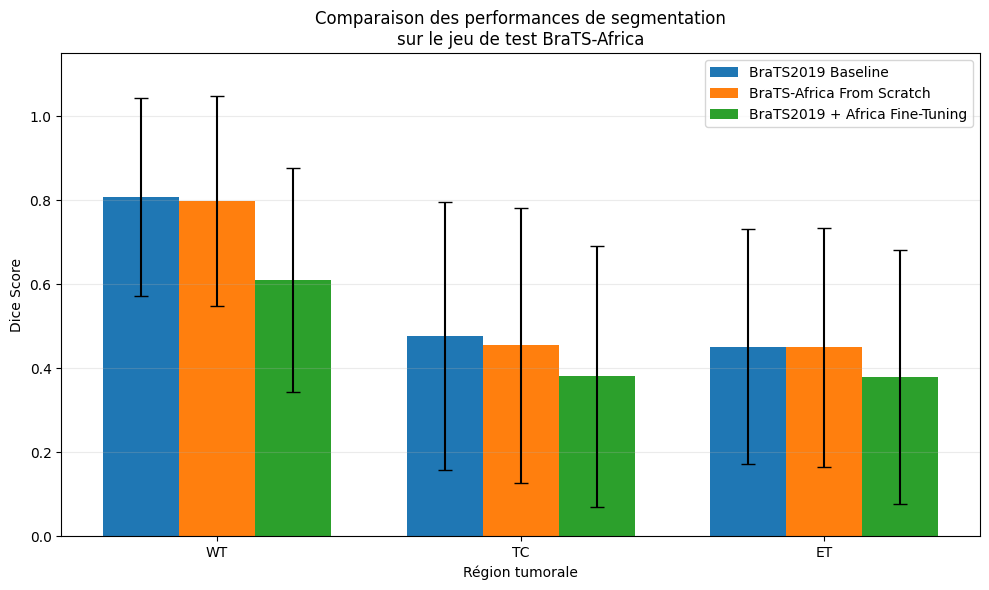

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Résultats finaux sur le test BraTS-Africa
regions = ["WT", "TC", "ET"]

baseline_mean = [0.8076, 0.4776, 0.4512]
baseline_std  = [0.2365, 0.3188, 0.2790]

africa_mean = [0.7975, 0.4549, 0.4496]
africa_std  = [0.2503, 0.3273, 0.2846]

finetune_mean = [0.6104, 0.3806, 0.3792]
finetune_std  = [0.2666, 0.3106, 0.3032]

x = np.arange(len(regions))
width = 0.25

plt.figure(figsize=(10, 6))

plt.bar(
    x - width, baseline_mean, width,
    yerr=baseline_std, capsize=5,
    label="BraTS2019 Baseline"
)

plt.bar(
    x, africa_mean, width,
    yerr=africa_std, capsize=5,
    label="BraTS-Africa From Scratch"
)

plt.bar(
    x + width, finetune_mean, width,
    yerr=finetune_std, capsize=5,
    label="BraTS2019 + Africa Fine-Tuning"
)

plt.xticks(x, regions)
plt.ylabel("Dice Score")
plt.xlabel("Région tumorale")
plt.ylim(0, 1.15)

plt.title(
    "Comparaison des performances de segmentation\n"
    "sur le jeu de test BraTS-Africa"
)

plt.legend()
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

# Sauvegarde en haute résolution
plt.savefig(
    "/content/drive/MyDrive/Master_SIIA/final_analysis/"
    "dice_three_models_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

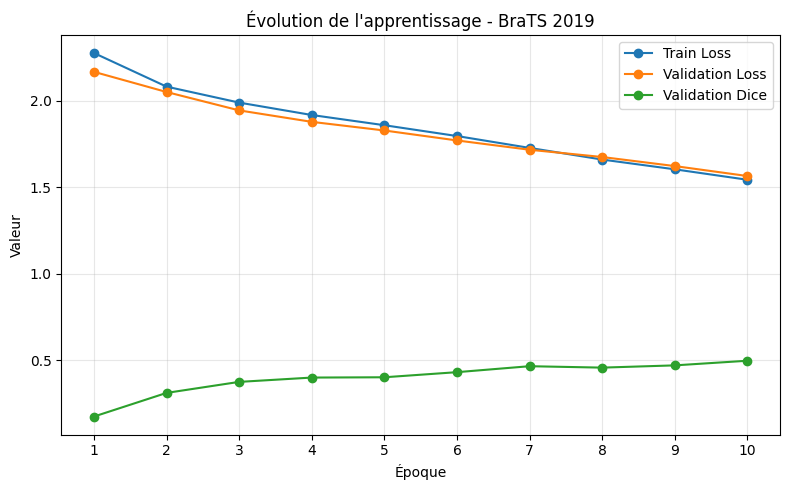

In [ ]:
import matplotlib.pyplot as plt

epochs = list(range(1, 11))

train_loss_2019 = [
    2.2762, 2.0818, 1.9895, 1.9177, 1.8587,
    1.7961, 1.7275, 1.6601, 1.6037, 1.5433
]

val_loss_2019 = [
    2.1673, 2.0507, 1.9444, 1.8781, 1.8282,
    1.7706, 1.7168, 1.6748, 1.6224, 1.5649
]

val_dice_2019 = [
    0.1740, 0.3107, 0.3744, 0.3994, 0.4011,
    0.4306, 0.4651, 0.4569, 0.4699, 0.4967
]

plt.figure(figsize=(8, 5))

plt.plot(epochs, train_loss_2019, marker='o', label='Train Loss')
plt.plot(epochs, val_loss_2019, marker='o', label='Validation Loss')
plt.plot(epochs, val_dice_2019, marker='o', label='Validation Dice')

plt.xlabel("Époque")
plt.ylabel("Valeur")
plt.title("Évolution de l'apprentissage - BraTS 2019")
plt.xticks(epochs)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("training_brats2019.png", dpi=300, bbox_inches="tight")
plt.show()

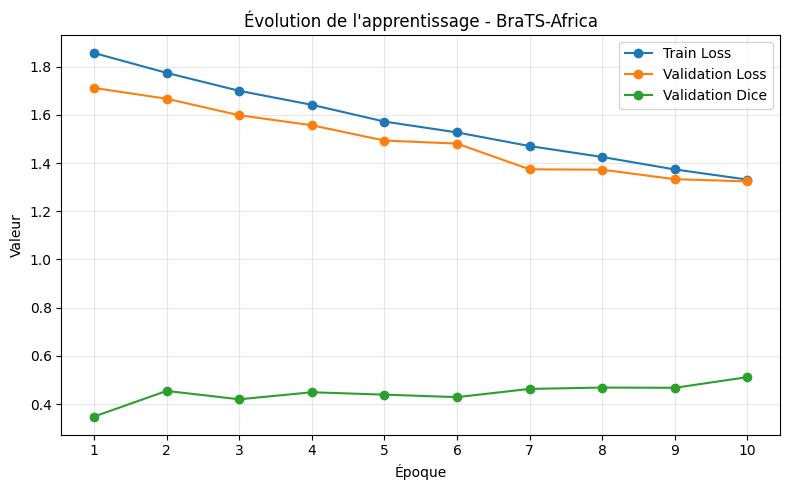

In [ ]:
train_loss_africa = [
    1.8561, 1.7737, 1.6993, 1.6413, 1.5718,
    1.5269, 1.4703, 1.4250, 1.3733, 1.3313
]

val_loss_africa = [
    1.7112, 1.6665, 1.5980, 1.5565, 1.4931,
    1.4805, 1.3738, 1.3723, 1.3330, 1.3237
]

val_dice_africa = [
    0.3487, 0.4550, 0.4202, 0.4494, 0.4395,
    0.4292, 0.4633, 0.4689, 0.4679, 0.5121
]

plt.figure(figsize=(8, 5))

plt.plot(epochs, train_loss_africa, marker='o', label='Train Loss')
plt.plot(epochs, val_loss_africa, marker='o', label='Validation Loss')
plt.plot(epochs, val_dice_africa, marker='o', label='Validation Dice')

plt.xlabel("Époque")
plt.ylabel("Valeur")
plt.title("Évolution de l'apprentissage - BraTS-Africa")
plt.xticks(epochs)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("training_brats_africa.png", dpi=300, bbox_inches="tight")
plt.show()